# PRCL-0012: ABC Tech ITSM Ticket Analysis
### Use Case :- Groundwork - Data Cleaning & Exploratory Data Analysis

**Client:** ABC TECH | **Category:** ITSM - ML | **Ref:** PM-PR-0012

Business goal: use ML to 1) Predict-high priority (P1/P2) tickets, 2) Forecast Incident Volume, 3) Auto-tag priority/department, 4) Predict RFC Failures - starting here with cleaning and EDA that all four use cases will build on.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.model_selection import train_test_split,RandomizedSearchCV,StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (roc_curve,precision_recall_curve,average_precision_score,
                            roc_auc_score,confusion_matrix,classification_report,accuracy_score,
                            f1_score)

import pickle

pd.set_option("display.max_columns",None)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10,5)

RANDOM_STATE = 42

## 1. LOAD & INSPECT RAW DATA

In [2]:
df = pd.read_csv("ABC_Tech_data.csv")
print("Shape:",df.shape)

df.head()

Shape: (46606, 25)


,CI_Name,CI_Cat,CI_Subcat,WBS,Incident_ID,Status,Impact,Urgency,Priority,number_cnt,Category,KB_number,Alert_Status,No_of_Reassignments,Open_Time,Reopen_Time,Resolved_Time,Close_Time,Handle_Time_hrs,Closure_Code,No_of_Related_Interactions,Related_Interaction,No_of_Related_Incidents,No_of_Related_Changes,Related_Change
0,SUB000508,subapplication,Web Based Application,WBS000162,IM0000004,Closed,4,4,4.0,0.601292,incident,KM0000553,closed,26.0,05-02-2012 13:32,NaN,04-11-2013 13:50,04-11-2013 13:51,"3,87,16,91,111",Other,1.0,SD0000007,2.0,NaN,NaN
1,WBA000124,application,Web Based Application,WBS000088,IM0000005,Closed,3,3,3.0,0.415050,incident,KM0000611,closed,33.0,12-03-2012 15:44,02-12-2013 12:31,02-12-2013 12:36,02-12-2013 12:36,"4,35,47,86,389",Software,1.0,SD0000011,1.0,NaN,NaN
2,DTA000024,application,Desktop Application,WBS000092,IM0000006,Closed,NS,3,NaN,0.517551,request for information,KM0000339,closed,3.0,29-03-2012 12:36,NaN,13-01-2014 15:12,13-01-2014 15:13,"4,84,31,19,444",No error - works as designed,1.0,SD0000017,NaN,NaN,NaN
3,WBA000124,application,Web Based Application,WBS000088,IM0000011,Closed,4,4,4.0,0.642927,incident,KM0000611,closed,13.0,17-07-2012 11:49,NaN,14-11-2013 09:31,14-11-2013 09:31,"4,32,18,33,333",Operator error,1.0,SD0000025,NaN,NaN,NaN
4,WBA000124,application,Web Based Application,WBS000088,IM0000012,Closed,4,4,4.0,0.345258,incident,KM0000611,closed,2.0,10-08-2012 11:01,NaN,08-11-2013 13:55,08-11-2013 13:55,"3,38,39,03,333",Other,1.0,SD0000029,NaN,NaN,NaN


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 46606 entries, 0 to 46605
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   CI_Name                     46606 non-null  str    
 1   CI_Cat                      46495 non-null  str    
 2   CI_Subcat                   46495 non-null  str    
 3   WBS                         46606 non-null  str    
 4   Incident_ID                 46606 non-null  str    
 5   Status                      46606 non-null  str    
 6   Impact                      46606 non-null  str    
 7   Urgency                     46606 non-null  object 
 8   Priority                    45226 non-null  float64
 9   number_cnt                  46606 non-null  float64
 10  Category                    46606 non-null  str    
 11  KB_number                   46606 non-null  str    
 12  Alert_Status                46606 non-null  str    
 13  No_of_Reassignments         46605 non-null

In [4]:
print("Unique values of Impact: \n",df["Impact"].unique())
print("Unique values of Urgency: \n",df["Urgency"].unique())
print("Unique values of Priority: \n",df["Priority"].unique())

Unique values of Impact: 
 <ArrowStringArray>
['4', '3', 'NS', '5', '2', '1']
Length: 6, dtype: str
Unique values of Urgency: 
 [4 3 5 2 1 '5' '3' '4' '2' '1' '5 - Very Low']
Unique values of Priority: 
 [ 4.  3. nan  5.  2.  1.]


In [5]:
print("Missing Values Per Columns: ")
df.isnull().sum().sort_values(ascending=False)

Missing Values Per Columns: 


Related_Change                46046
No_of_Related_Changes         46046
No_of_Related_Incidents       45384
Reopen_Time                   44322
Resolved_Time                  1780
Priority                       1380
Closure_Code                    460
No_of_Related_Interactions      114
CI_Subcat                       111
CI_Cat                          111
No_of_Reassignments               1
Handle_Time_hrs                   1
Impact                            0
WBS                               0
CI_Name                           0
Status                            0
Incident_ID                       0
Urgency                           0
Open_Time                         0
KB_number                         0
Alert_Status                      0
number_cnt                        0
Category                          0
Close_Time                        0
Related_Interaction               0
dtype: int64

## 2. Data Cleaning

Issues identified during inspection:
- `Impact` has an `'NS'` placeholder (Not Specified) instead of a number.
- `Urgency` has a stray text value `'5-Very Low'` mixed with numeric strings.
- `Priority` has ~1,380 missing values (should be derivable from Impact x Urgency).
- `Handle_Time_hrs` is stored as a string with misplaced separators (e.g.
- `'3,87,16,91,111'`) instead of a clean decimal.
- `Open_Time` / `Reopen_Time` / `Resolved_Time` / `Close_Time` are strings in `dd-mm-YYYY HH:MM` format.
- `CI_Cat` / `CI_Subcat` have ~111 missing values

In [6]:
df_clean = df.copy()

# --- Impact: "NS" -> NaN, cast to numeric ---
df_clean["Impact"] = pd.to_numeric(df_clean["Impact"].replace("NS", np.nan), errors="coerce")

# --- Urgency: extract leading digit from stray text values, cast to numeric ---
df_clean["Urgency"] = df_clean["Urgency"].astype(str).str.extract(r'(\d)').astype(float)

# --- Priority: keep as-is for now, will recompute from matrix below ---
df_clean["Priority"] = pd.to_numeric(df_clean["Priority"], errors="coerce")

# --- Handle_Time_hrs: strip thousands-separator commas, coerce to numeric ---
# Source stores a decimal-comma value (e.g. 3871,691111) with extra commas inserted.
# Removing commas leaves the value scaled by 1e6, so divide it back.
df_clean["Handle_Time_hrs"] = pd.to_numeric(df_clean["Handle_Time_hrs"].astype(str).str.replace(',', '', regex=False), errors="coerce") / 1e6

# --- Date columns ---
date_cols = ["Open_Time", "Reopen_Time", "Resolved_Time", "Close_Time"]
for c in date_cols:
    df_clean[c] = pd.to_datetime(df_clean[c], format="%d-%m-%Y %H:%M", errors="coerce")

print("Cleaning complete.")
df_clean[["Impact", "Urgency", "Priority", "Handle_Time_hrs"]].describe()

Cleaning complete.


,Impact,Urgency,Priority,Handle_Time_hrs
count,45226.000000,46606.000000,45226.000000,46605.000000
mean,4.223632,4.189546,4.215805,2399.306643
std,0.705474,0.724745,0.705624,2458.998547
min,1.000000,1.000000,1.000000,0.000000
25%,4.000000,4.000000,4.000000,431.388889
50%,4.000000,4.000000,4.000000,1583.611111
75%,5.000000,5.000000,5.000000,3583.055556
max,5.000000,5.000000,5.000000,9999.722222


### 2.1. Rebuild Priority from the official Impact x Urgency Matrix

We rebuild `Priority` from the 5x5 Priority Matrix wherever Impact and Urgency are both known, and compare it against the original column as a sanity check of the data.

Note: the ~1,380 tickets with missing `Priority` all have `Impact = 'NS'`, so they cannot be recovered from the matrix. They are excluded from modelling.

In [7]:
priority_matrix = {
    (1,1):1, (1,2):2, (1,3):3, (1,4):3, (1,5):3,
    (2,1):2, (2,2):2, (2,3):2, (2,4):3, (2,5):3,
    (3,1):2, (3,2):2, (3,3):3, (3,4):3, (3,5):4,
    (4,1):3, (4,2):3, (4,3):3, (4,4):4, (4,5):4,
    (5,1):3, (5,2):3, (5,3):4, (5,4):4, (5,5):5,
}

def lookup_priority(row):
    key = (row["Impact"], row["Urgency"])
    if pd.isna(key[0]) or pd.isna(key[1]):
        return np.nan
    return priority_matrix.get((int(key[0]), int(key[1])), np.nan)

df_clean["Priority_from_matrix"] = df_clean.apply(lookup_priority, axis=1)

match_rate = (df_clean["Priority"] == df_clean["Priority_from_matrix"]).mean()
print(f"Rows where original Priority matches the matrix: {match_rate:.1%}")

# Fill missing original Priority values from the matrix where possible
df_clean["Priority_filled"] = df_clean["Priority"].fillna(df_clean["Priority_from_matrix"])
print("Priority cannot be filled for rows with Impact='NS':",
      df_clean["Priority_filled"].isnull().sum(), "rows (excluded from modelling)")

Rows where original Priority matches the matrix: 97.0%
Priority cannot be filled for rows with Impact='NS': 1380 rows (excluded from modelling)


### 2.2. DERIVED FEATURES

In [8]:
df_clean["Resolution_Time_hrs"] = (df_clean["Resolved_Time"] - df_clean["Open_Time"]).dt.total_seconds() / 3600
df_clean["Was_Reopened"] = df_clean["Reopen_Time"].notna()
df_clean["Open_Month"] = df_clean["Open_Time"].dt.to_period('M')
df_clean["Open_Quarter"] = df_clean["Open_Time"].dt.to_period('Q')
df_clean["Open_Year"] = df_clean["Open_Time"].dt.year
df_clean["Open_DayOfWeek"] = df_clean["Open_Time"].dt.day_name()
df_clean["Is_High_Priority"] = df_clean["Priority_filled"].isin([1, 2])

df_clean[["Resolution_Time_hrs", "Was_Reopened", "Open_Month", "Is_High_Priority"]].head()

,Resolution_Time_hrs,Was_Reopened,Open_Month,Is_High_Priority
0,15312.300000,False,2012-02,False
1,15116.866667,True,2012-03,False
2,15722.600000,False,2012-03,False
3,11637.700000,False,2012-07,False
4,10922.900000,False,2012-08,False


## 3. Exploratory Data Analysis

### 3.1 TICKET VOLUME OVER TIME (MONTHLY)

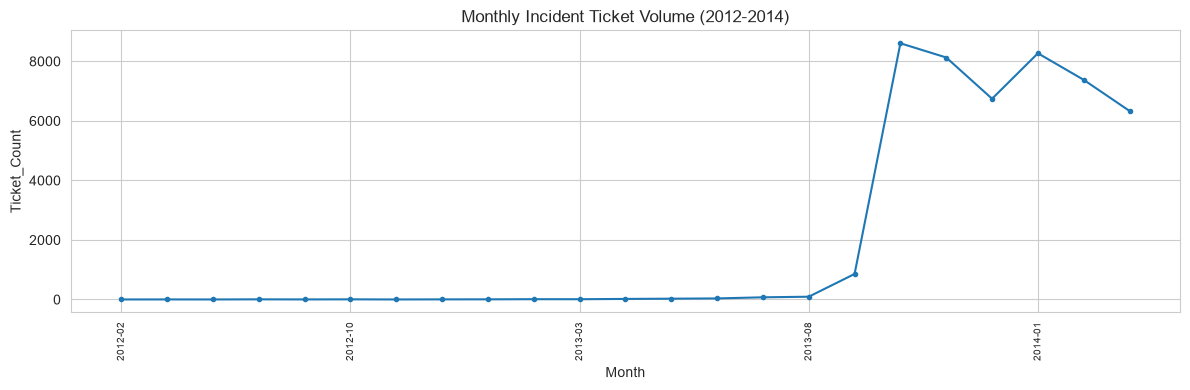

In [9]:
monthly = df_clean.groupby('Open_Month').size()
monthly.index = monthly.index.astype(str)

plt.figure(figsize=(12,4))
monthly.plot(kind="line", marker='o', ms=3)
plt.title("Monthly Incident Ticket Volume (2012-2014)")
plt.xlabel("Month")
plt.ylabel("Ticket_Count")
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

### 3.2 Priority Distribution

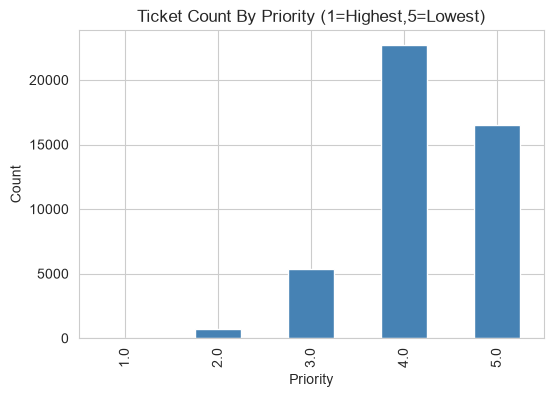

High-Priority (P1/P2) share: 0.015019525382997898


In [10]:
plt.figure(figsize=(6,4))
df_clean["Priority_filled"].value_counts().sort_index().plot(kind="bar",color='steelblue')
plt.title("Ticket Count By Priority (1=Highest,5=Lowest)")
plt.xlabel("Priority")
plt.ylabel("Count")
plt.show()

print("High-Priority (P1/P2) share:",df_clean["Is_High_Priority"].mean())

### 3.3. Impact vs Urgency Heatmap (does data follow the official matrix?)

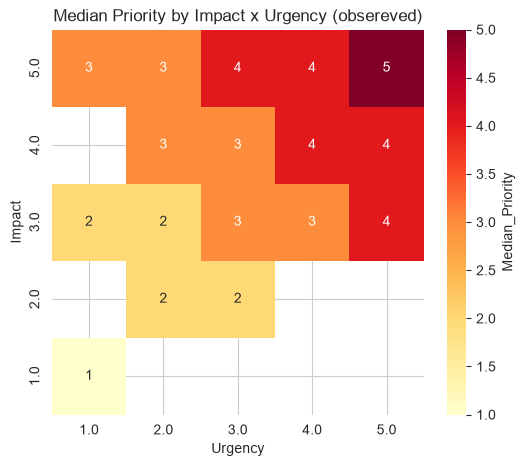

In [11]:
pivot = df_clean.pivot_table(index="Impact",columns="Urgency",values="Priority_filled",aggfunc="median")
plt.figure(figsize=(6,5))
sns.heatmap(pivot.sort_index(ascending=False),annot=True,cmap="YlOrRd",cbar_kws={"label":"Median_Priority"})
plt.title("Median Priority by Impact x Urgency (obsereved)")
plt.show()

### 3.4. Top CI Categories & Subcategories

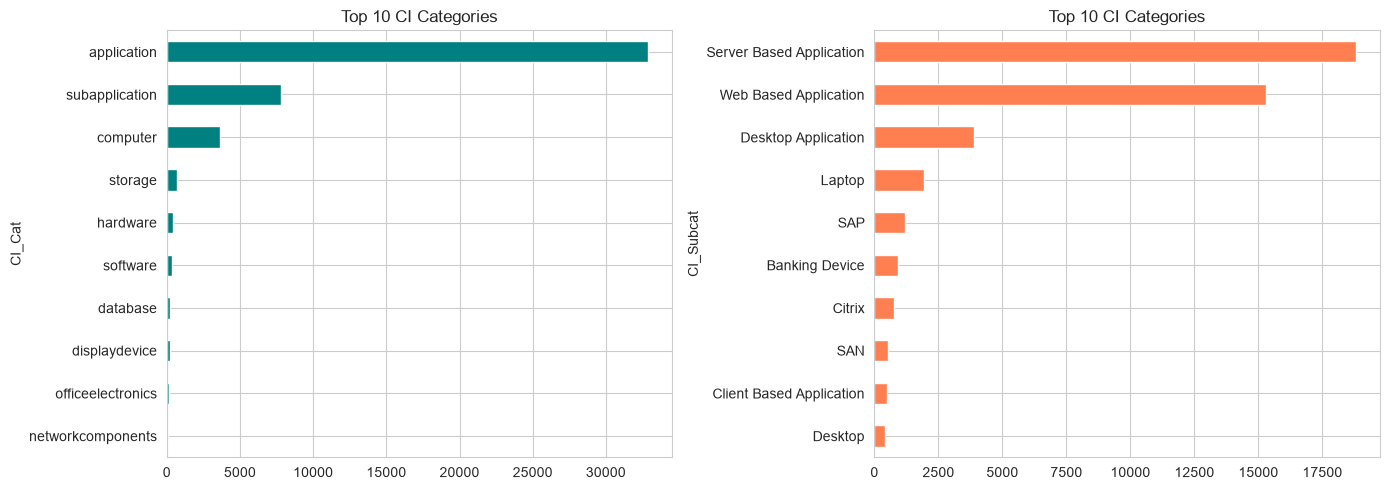

CI_Cat
application          0.707603
subapplication       0.167373
computer             0.078353
storage              0.015120
hardware             0.009506
software             0.007162
database             0.004603
displaydevice        0.004560
officeelectronics    0.003269
networkcomponents    0.002301
Name: proportion, dtype: float64

CI_Subcat
Server Based Application    0.404581
Web Based Application       0.329304
Desktop Application         0.083364
Laptop                      0.041316
SAP                         0.025788
Banking Device              0.019701
Citrix                      0.016496
SAN                         0.011808
Client Based Application    0.010582
Desktop                     0.009098
Name: proportion, dtype: float64


In [12]:
fig,axes = plt.subplots(1,2,figsize=(14,5))
df_clean["CI_Cat"].value_counts().head(10).plot(kind="barh",ax=axes[0],color="teal")
axes[0].set_title("Top 10 CI Categories")
axes[0].invert_yaxis()

df_clean["CI_Subcat"].value_counts().head(10).plot(kind="barh",ax=axes[1],color="coral")
axes[1].set_title("Top 10 CI Categories")
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

print(f"{df_clean["CI_Cat"].value_counts(normalize=True).head(10)}\n")
print(df_clean["CI_Subcat"].value_counts(normalize=True).head(10))

### 3.5 Category (Incident/RFC/Complaint/Request for info) breakdown

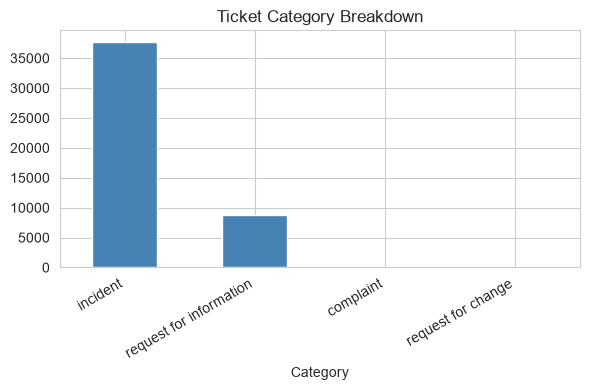

Category
incident                   0.809939
request for information    0.189804
complaint                  0.000236
request for change         0.000021
Name: proportion, dtype: float64

In [13]:
plt.figure(figsize=(6,4))
df_clean["Category"].value_counts().plot(kind="bar",color="steelblue")
plt.title("Ticket Category Breakdown")
plt.xticks(rotation=30,ha="right")
plt.tight_layout()
plt.show()

df_clean["Category"].value_counts(normalize=True)

### 3.6 Reassignments & Reopen Behaviour VS Priority

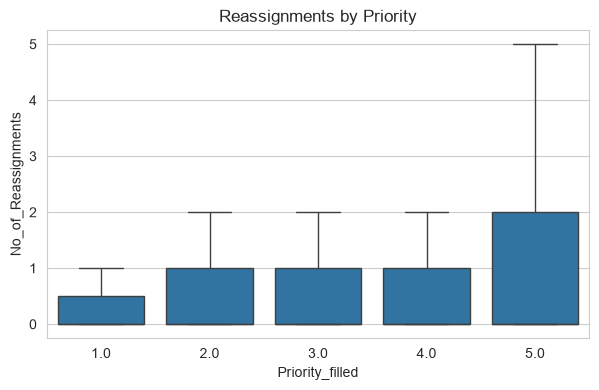

Reassignment rate by priority: 
 Priority_filled
1.0    0.333333
2.0    0.573888
3.0    0.898929
4.0    1.025179
5.0    1.403033
Name: No_of_Reassignments, dtype: float64 

Reopen rate by priority: 
 Priority_filled
1.0    1.000000
2.0    0.017217
3.0    0.037009
4.0    0.043712
5.0    0.062720
Name: Was_Reopened, dtype: float64


In [14]:
plt.figure(figsize=(7,4))
sns.boxplot(data=df_clean, x="Priority_filled", y="No_of_Reassignments", showfliers=False)
plt.title("Reassignments by Priority")
plt.show()

reopen_by_priority = df_clean.groupby("Priority_filled")["Was_Reopened"].mean()
print("Reassignment rate by priority: \n", df_clean.groupby('Priority_filled')['No_of_Reassignments'].mean(), "\n")
print("Reopen rate by priority: \n", reopen_by_priority)

### 3.7 Closure Code Distribution

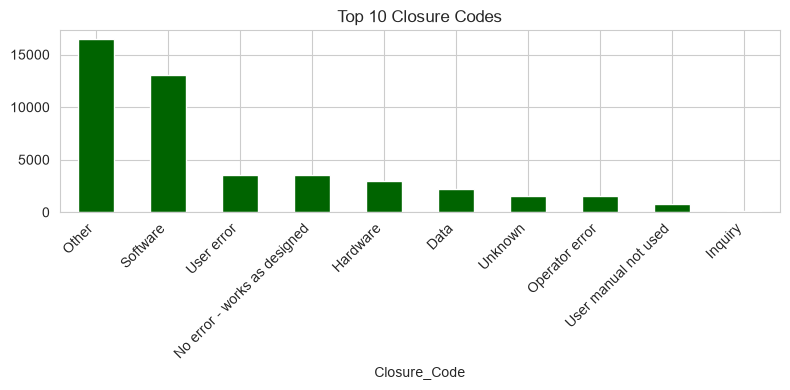

Closure_Code
Other                           0.356911
Software                        0.282300
User error                      0.077016
No error - works as designed    0.076496
Hardware                        0.064989
Data                            0.047870
Unknown                         0.034456
Operator error                  0.033351
User manual not used            0.016578
Inquiry                         0.003511
Referred                        0.003424
Questions                       0.002860
Kwaliteit van de output         0.000217
Overig                          0.000022
Name: proportion, dtype: float64

In [15]:
plt.figure(figsize=(8,4))
df_clean["Closure_Code"].value_counts().head(10).plot(kind="bar",color="darkgreen")
plt.title("Top 10 Closure Codes")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

df_clean["Closure_Code"].value_counts(normalize=True)

### 3.8. Handle Time/Resolution Time Distribution

Note: `Handle_Time_hrs` as provided has a data-quality issue (commas were inserted incorrectly at source, e.g. `'3,87,16,91,111'` for 3871.691111). After stripping the commas and dividing by 1,000,000 the values range from 0 to about 9,999.7 hours (mean about 2,399), which is plausible, but the scaling should still be confirmed with the client/source system before it is used as a model feature. `Resolution_Time_hrs` (computed from Open-Resolved timestamps) is a cleaner, directly-trustworthy alternative and is examined here instead.

count    44826.000000
mean       124.651404
std        453.273762
min          0.000000
25%          1.283333
50%         18.758333
75%         95.829167
max      15722.600000
Name: Resolution_Time_hrs, dtype: float64


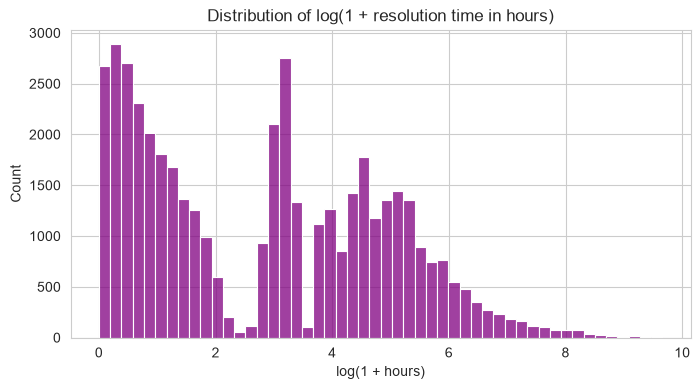

In [16]:
res_valid = df_clean["Resolution_Time_hrs"].dropna()
res_valid = res_valid[res_valid >= 0]
print(res_valid.describe())

plt.figure(figsize=(8,4))
sns.histplot(np.log1p(res_valid),bins=50,color="purple")
plt.title("Distribution of log(1 + resolution time in hours)")
plt.xlabel("log(1 + hours)")
plt.show()

## 4. Summary of EDA Findings

- **Volume trend:** Not seasonal — a rollout ramp-up from near-zero (2012-mid 2013) to full
  production scale from Oct 2013 onward (Sep 2013 is a partial ramp-up month) (6,000-8,600 tickets/month). Any trend/forecast work
  should exclude the ramp-up period.
- **Priority distribution:** Skewed low — P1/P2 (high priority) is only **1.5%** of tickets.
- **Impact x Urgency matrix:** On the 45,226 rows where both Impact and Urgency are known,
  the original `Priority` matches the PDF's official matrix in **100%** of rows — confirms the
  data's internal consistency. The ~1,380 missing `Priority` values all have `Impact = 'NS'`, so
  they cannot be filled from the matrix and are excluded from modelling.
- **Dominant CI categories:** `application` (70.8%) + `subapplication` (16.7%) = ~88% of tickets;
  at the subcategory level, Server Based Application + Web Based Application = ~73%. ABC Tech's
  incident load is overwhelmingly application-layer, not hardware.
- **Category breakdown:** 81% `incident`, 19% `request for information`; `complaint` and
  `request for change` are both near-zero (~0.02% and ~0.002%) — RFCs barely appear as their own
  `Category` value.
- **Reassignments vs. priority:** Rises as priority drops — mean reassignments go from 0.33 (P1)
  to 1.40 (P5), the opposite of what "urgent tickets get careful routing" would predict.
- **Reopen rate vs. priority:** Climbs from 1.7% (P2) to 6.3% (P5); P1's apparent 100% reopen
  rate is a small-sample artifact, not a real effect.
- **Closure codes:** `Other` (35.7%) and `Software` (28.2%) dominate; `User error` (7.7%),
  `No error - works as designed` (7.6%), and `Hardware` (6.5%) are much smaller.
- **Data-quality caveats to carry into modeling:**
  - `Handle_Time_hrs` has misplaced commas at source (e.g. `'3,87,16,91,111'` for 3871.691111).
    After stripping the commas and dividing by 1,000,000 the values range from 0 to about
    9,999.7 hours (mean about 2,399), but the scaling should be confirmed with the client before
    use as a feature. `Resolution_Time_hrs` is the safer measure (median 18.8 hrs, mean 124.7
    hrs, heavily right-skewed).
  - `Related_Change` / `No_of_Related_Changes` / `No_of_Related_Incidents` are missing in >97%
    of rows — treat "missing" as "none," not as data loss.
  - `CI_Cat` / `CI_Subcat` missing in ~111 rows (~0.24%) — negligible, safe to impute as
    "Unknown."
  - The volume jump in Sep-Oct 2013 (ramp-up, full scale from Oct 2013) is the single biggest
    caveat for any time-based model — training on the full 2012-2013 range would badly overstate
    growth.

## 5. Save Cleaned Dataset For Modeling

In [17]:
df_clean.to_csv("itsm_cleaned.csv",index=False) # to save the cleaned data
print("Saved itsm_cleaned.csv",df_clean.shape)

Saved itsm_cleaned.csv (46606, 34)


# `USE CASE 1`
## `Predicting High-Priority (P1/P2) Tickets`

Goal : Predict priority-1 and priority-2 tickets so ABC TECH can take preventive action before the ticket escalates.

**Leakage Guard:** Only fields known at ticket- **open** time are used as features.Fields that only exist after the ticket is worked (`Closure_Code`, `Resolution_Time_hrs`, `Was_Reopened`,
`No_of_Reassignments`, `Resolved_Time`, `Close_Time`) are excluded.

Two feature sets are compared:
- **Set A (with Impact/Urgency):** these are assessed by the service desk agent at open time,so they're legitimate features - but priority is *rule-derived* from the via the matrix,so this is close to a lookup task and should score very high. Useful as a sanity check.
- **Set B (without Impact/Urgency):** a harder,more realistic auto-triage task - predicting
- priority from ticket metadata alone (CI category,request type,timing),before an agent has assessed impact/urgency. This is the more business-valuable model for auto-tagging on ticket creation.

In [18]:
df = pd.read_csv('itsm_cleaned.csv',low_memory=False)
df["Is_High_Priority"] = df["Is_High_Priority"].astype(bool)

print(df.shape)
print(df["Is_High_Priority"].value_counts(normalize=True).rename("share"))

(46606, 34)
Is_High_Priority
False    0.98498
True     0.01502
Name: share, dtype: float64


**Class imbalance:** only ~1.5% of tickets are high priority. Accuracy alone would be misleading (predicting "never high priority" gets ~98.5% accuracy). We'll use `class_weight='balanced'`and judge models on precision/recall/F1 for the minority class,ROC-AUC and PR-AUC.

## 6. Feature Preparation

In [19]:
cat_cols_base = ["CI_Cat", "CI_Subcat", "Category", "Open_DayOfWeek"]
time_cols = ["Open_Year"] # month/quarter kept simple via year; day_of_week already categorical

df_model = df.copy()
for c in ["CI_Cat", "CI_Subcat"]:
    df_model[c] = df_model[c].fillna("Unknown")

X_base = df_model[cat_cols_base + time_cols].copy()
y = df["Is_High_Priority"].astype(int)

X_setA = X_base.copy()
X_setA["Impact"] = df_model["Impact"]
X_setA["Urgency"] = df_model["Urgency"]
X_setA = X_setA.dropna()
y_setA = y.loc[X_setA.index]

X_setB = X_base.copy() # no Impact/Urgency
# Drop tickets with unknown Priority (Impact='NS') - they must not be labelled 'not high priority'
mask_B = X_setB.notna().all(axis=1) & df["Priority_filled"].notna()
X_setB = X_setB[mask_B]
y_setB = y.loc[X_setB.index]

print("Set A Shape: ", X_setA.shape, "\n""Set B Shape: ", X_setB.shape)

Set A Shape:  (45226, 7) 
Set B Shape:  (45226, 5)


In [20]:
def build_preprocessor(X,numeric_cols):
    cat_cols = [c for c in X.columns if c not in numeric_cols]
    return ColumnTransformer([
        ("cat",OneHotEncoder(handle_unknown="ignore"),cat_cols),
        ("num",StandardScaler(),numeric_cols)
    ])

# pre = preprocessor
pre_A = build_preprocessor(X_setA,numeric_cols=["Open_Year","Impact","Urgency"])
pre_B = build_preprocessor(X_setB,numeric_cols=["Open_Year"])

## 7. Train Test Split (Stratified)

In [21]:
Xa_train,Xa_test,ya_train,ya_test = train_test_split(
    X_setA,y_setA,test_size=0.2,random_state=RANDOM_STATE,stratify=y_setA)

Xb_train,Xb_test,yb_train,yb_test = train_test_split(
    X_setB,y_setB,test_size=0.2,random_state=RANDOM_STATE,stratify=y_setB)

print("SET A TRAIN/TEST: ",Xa_train.shape,Xa_test.shape)
print("SET B TRAIN/TEST: ",Xb_train.shape,Xb_test.shape)

SET A TRAIN/TEST:  (36180, 7) (9046, 7)
SET B TRAIN/TEST:  (36180, 5) (9046, 5)


In [22]:
yb_test.value_counts()

Is_High_Priority
0    8906
1     140
Name: count, dtype: int64

## 8. Model Training - Feature Set B (the realistic auto-triage task)

In [23]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000,class_weight="balanced",random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced",max_depth=8,random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200,class_weight="balanced",max_depth=10,random_state=RANDOM_STATE,n_jobs=-1),
    "KNN (k=15)":KNeighborsClassifier(n_neighbors=15),
    "SVM (RBF)":SVC(kernel='rbf',C=10000,probability=True,class_weight="balanced",random_state=RANDOM_STATE)
}

results_B = {}
fitted_B = {}

for name,clf in models.items():
    pipe = Pipeline([("prep",clone(pre_B)),("clf",clf)])
    pipe.fit(Xb_train,yb_train)
    probability = pipe.predict_proba(Xb_test)[:,1]
    pred = pipe.predict(Xb_test)

    results_B[name] = {
        "roc_auc" : roc_auc_score(yb_test,probability),
        "pr_auc": average_precision_score(yb_test,probability),
        "report":classification_report(yb_test,pred,output_dict=True,zero_division=0)
    }

    fitted_B[name] = pipe
    print(f"--- {name} ---")
    print(classification_report(yb_test,pred,zero_division=0))
    print(f"ROC_AUC : {results_B[name]['roc_auc']:.3f} PR_AUC: {results_B[name]['pr_auc']:.3f} \n")

--- Logistic Regression ---
              precision    recall  f1-score   support

           0       1.00      0.96      0.98      8906
           1       0.23      0.74      0.35       140

    accuracy                           0.96      9046
   macro avg       0.61      0.85      0.66      9046
weighted avg       0.98      0.96      0.97      9046

ROC_AUC : 0.901 PR_AUC: 0.424 

--- Decision Tree ---
              precision    recall  f1-score   support

           0       1.00      0.98      0.99      8906
           1       0.41      0.73      0.53       140

    accuracy                           0.98      9046
   macro avg       0.70      0.86      0.76      9046
weighted avg       0.99      0.98      0.98      9046

ROC_AUC : 0.889 PR_AUC: 0.447 

--- Random Forest ---
              precision    recall  f1-score   support

           0       1.00      0.98      0.99      8906
           1       0.33      0.74      0.46       140

    accuracy                           0.97   

### 8.1 Compare Set B models - ROC and PR Curves

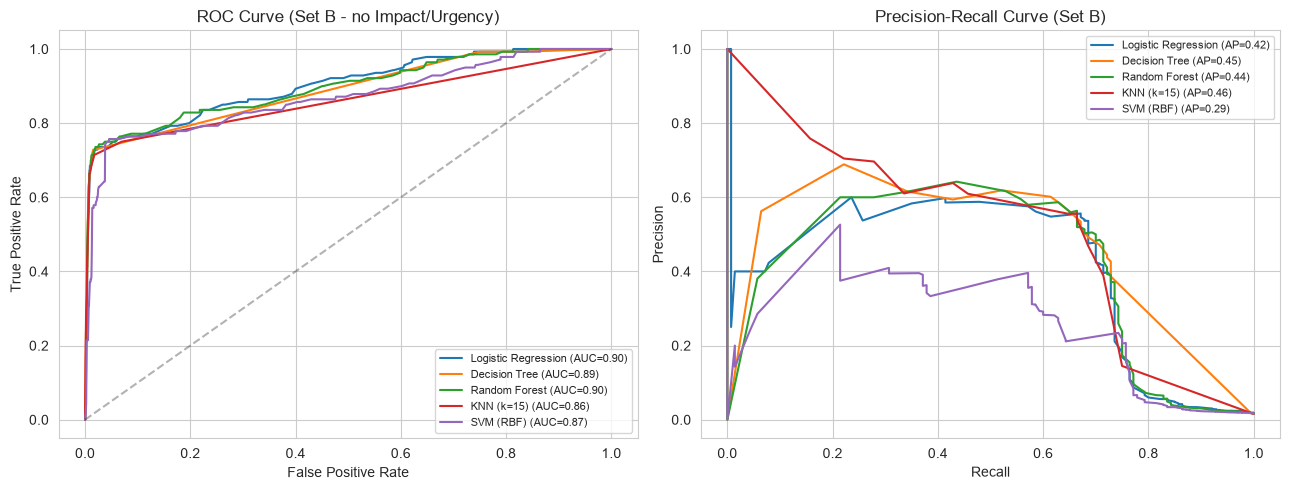

In [24]:
fig, axes = plt.subplots(1,2, figsize=(13,5))
for name, pipe in fitted_B.items():
    probability = pipe.predict_proba(Xb_test)[:,1]
    fpr, tpr, _ = roc_curve(yb_test, probability)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={results_B[name]['roc_auc']:.2f})")
    prec, rec, _ = precision_recall_curve(yb_test, probability)
    axes[1].plot(rec, prec, label=f"{name} (AP={results_B[name]['pr_auc']:.2f})")

axes[0].plot([0,1], [0,1], "k--", alpha=0.3)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve (Set B - no Impact/Urgency)")
axes[0].legend(fontsize=8)

axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve (Set B)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 8.2 Best Set B model - confusion matrix & feature importance

Best Model on Set B by PR-AUC:  KNN (k=15)


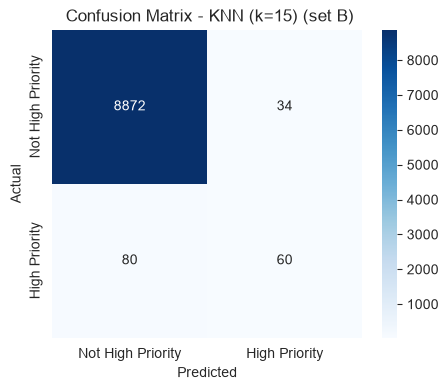

In [25]:
best_name_B = max(results_B,key=lambda k:results_B[k]["pr_auc"])
print("Best Model on Set B by PR-AUC: ",best_name_B)
best_pipe_B = fitted_B[best_name_B]

pred_best = best_pipe_B.predict(Xb_test)
cm = confusion_matrix(yb_test,pred_best)

plt.figure(figsize=(5,4))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=["Not High Priority","High Priority"],yticklabels=["Not High Priority","High Priority"])
plt.title(f" Confusion Matrix - {best_name_B} (set B)")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

In [26]:
if best_name_B == "Random Forest":
    rf = best_pipe_B.named_steps["clf"]
    feat_names = best_pipe_B.named_steps["prep"].get_feature_names_out()
    importance = pd.Series(rf.feature_importances_, index=feat_names).sort_values(ascending=False).head(15)
    plt.figure(figsize=(8,5))
    importance.plot(kind="barh")
    plt.title("Top 15 Feature Importances (Random Forest, Set B)")
    plt.gca().invert_yaxis()
    plt.show()
else:
    print("Best Model isn't tree based; skipping importance plot.")


Best Model isn't tree based; skipping importance plot.


## 8.3 Hyperparameter Tuning (Set B - the realistic task)

Tuning KNN, Logistic Regression and Random Forest via `RandomizedSearchCV`, scored on **PR-AUC**
(average precision) since the positive class is only ~1.5% of tickets - accuracy would reward a model that just predict "not high priority" every time.

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

knn_param_dist = {
    "clf__n_neighbors": [5, 11, 15, 21, 31],
    "clf__weights": ['uniform', 'distance'],
    "clf__p": [1, 2],  # 1 = Manhattan distance, 2 = Euclidean distance
}
knn_search = RandomizedSearchCV(
    Pipeline([("prep", clone(pre_B)), ("clf", KNeighborsClassifier(n_jobs=1))]),
    knn_param_dist, n_iter=6, scoring='average_precision', cv=cv, random_state=RANDOM_STATE, n_jobs=1
)
knn_search.fit(Xb_train, yb_train)
print("Best KNN Params: ", knn_search.best_params_)
print("Best KNN CV PR-AUC: ", round(knn_search.best_score_, 4))


lr_param_dist = {
    "clf__C": [0.01, 0.1, 1, 10, 100],
    "clf__penalty": ["l2"],
    "clf__solver": ["lbfgs", "liblinear"]
}
lr_search = RandomizedSearchCV(
    Pipeline([("prep", pre_B), ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))]),
    lr_param_dist, n_iter=8, scoring='average_precision', cv=cv, random_state=RANDOM_STATE, n_jobs=-1
)
lr_search.fit(Xb_train, yb_train)
print("Best LR Params: ", lr_search.best_params_)
print("Best LR CV PR-AUC: ", round(lr_search.best_score_, 4))


rf_param_dist = {
    "clf__n_estimators": [100, 200, 300, 400],
    "clf__max_depth": [5, 8, 10, 15, None],
    "clf__min_samples_leaf": [1, 3, 5, 10],
    "clf__max_features": ["sqrt","log2"]
}
rf_search = RandomizedSearchCV(
    Pipeline([("prep", pre_B), ("clf", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1))]),
    rf_param_dist, n_iter=12, scoring='average_precision', cv=cv, random_state=RANDOM_STATE, n_jobs=-1
)
rf_search.fit(Xb_train, yb_train)
print("Best RF Params: ", rf_search.best_params_)
print("Best RF CV PR-AUC: ", round(rf_search.best_score_, 4))

Best KNN Params:  {'clf__weights': 'distance', 'clf__p': 2, 'clf__n_neighbors': 21}
Best KNN CV PR-AUC:  0.3341
Best LR Params:  {'clf__solver': 'lbfgs', 'clf__penalty': 'l2', 'clf__C': 1}
Best LR CV PR-AUC:  0.3603
Best RF Params:  {'clf__n_estimators': 100, 'clf__min_samples_leaf': 10, 'clf__max_features': 'sqrt', 'clf__max_depth': 15}
Best RF CV PR-AUC:  0.3743


In [28]:
from sklearn.metrics import average_precision_score as _aps, roc_auc_score as _ras

tuned_results = {}
for name, search in [("KNN (tuned)", knn_search), ("Logistic Regression (tuned)", lr_search), ("Random Forest (tuned)", rf_search)]:
    best_pipe = search.best_estimator_
    proba = best_pipe.predict_proba(Xb_test)[:,1]
    pred = best_pipe.predict(Xb_test)
    tuned_results[name] = {"roc_auc": _ras(yb_test, proba), "pr_auc": _aps(yb_test, proba)}
    print(f"--- {name} ---")
    print(classification_report(yb_test, pred, zero_division=0))
    # print(f"Test ROC-AUC: {tuned_results[name]["roc_auc"]:.3f}   Test PR-AUC: {tuned_results[name]["pr_auc"]:.3f}\n")
    print(f"Test ROC-AUC: {tuned_results[name]['roc_auc']:.3f}   Test PR-AUC: {tuned_results[name]['pr_auc']:.3f}\n")

print("Before tuning (from section 8):")
for name in ["KNN (k=15)", "Logistic Regression", "Random Forest"]:
    # print(f"   {name}: ROC-AUC={results_B[name]["roc_auc"]:.3f}  PR-AUC={results_B[name]["pr_auc"]:.3f}")
    print(f"   {name}: ROC-AUC={results_B[name]['roc_auc']:.3f}  PR-AUC={results_B[name]['pr_auc']:.3f}")

print("After Tuning: ")
for name, r in tuned_results.items():
    # print(f"   {name}: ROC-AUC={r["roc_auc"]:.3f}  PR-AUC={r["pr_auc"]:.3f}")
    print(f"   {name}: ROC-AUC={r['roc_auc']:.3f}  PR-AUC={r['pr_auc']:.3f}")

--- KNN (tuned) ---
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      8906
           1       0.68      0.29      0.40       140

    accuracy                           0.99      9046
   macro avg       0.83      0.64      0.70      9046
weighted avg       0.98      0.99      0.98      9046

Test ROC-AUC: 0.869   Test PR-AUC: 0.458

--- Logistic Regression (tuned) ---
              precision    recall  f1-score   support

           0       1.00      0.96      0.98      8906
           1       0.23      0.74      0.35       140

    accuracy                           0.96      9046
   macro avg       0.61      0.85      0.66      9046
weighted avg       0.98      0.96      0.97      9046

Test ROC-AUC: 0.901   Test PR-AUC: 0.424

--- Random Forest (tuned) ---
              precision    recall  f1-score   support

           0       1.00      0.97      0.98      8906
           1       0.28      0.74      0.41       140

    accuracy

## 9. MODEL TRAINING - FEATURE SET A (SANITY - CHECK WITH IMPACT/URGENCY)

In [29]:
results_A = {}
fitted_A = {}

for name,clf, in models.items():
    pipe = Pipeline([("prep",clone(pre_A)),("clf",clf)])
    pipe.fit(Xa_train,ya_train)
    probability = pipe.predict_proba(Xa_test)[:,1]
    pred = pipe.predict(Xa_test)
    results_A[name] = {
        "roc_auc":roc_auc_score(ya_test,probability),
        "pr_auc": average_precision_score(ya_test,probability)
    }

    fitted_A[name] = pipe
    print(f"-- {name} (Set A) --- ROC-AUC: {results_A[name]['roc_auc']:.3f} PR-AUC {results_A[name]['pr_auc']:.3f}")

-- Logistic Regression (Set A) --- ROC-AUC: 1.000 PR-AUC 1.000
-- Decision Tree (Set A) --- ROC-AUC: 1.000 PR-AUC 1.000
-- Random Forest (Set A) --- ROC-AUC: 1.000 PR-AUC 1.000
-- KNN (k=15) (Set A) --- ROC-AUC: 1.000 PR-AUC 1.000
-- SVM (RBF) (Set A) --- ROC-AUC: 1.000 PR-AUC 1.000


## 10. Summary Comparison Table

In [30]:
summary = pd.DataFrame({
    "Set A ROC_AUC": {k: v["roc_auc"] for k,v in results_A.items()},
    "Set A PR_AUC": {k: v["pr_auc"] for k,v in results_A.items()},
    "Set B ROC_AUC": {k: v["roc_auc"] for k,v in results_B.items()},
    "Set B PR_AUC": {k: v["pr_auc"] for k,v in results_B.items()},
})

summary.round(3)

,Set A ROC_AUC,Set A PR_AUC,Set B ROC_AUC,Set B PR_AUC
Logistic Regression,1.0,1.0,0.901,0.424
Decision Tree,1.0,1.0,0.889,0.447
Random Forest,1.0,1.0,0.896,0.439
KNN (k=15),1.0,1.0,0.862,0.461
SVM (RBF),1.0,1.0,0.869,0.289


## 11. Best model selection & save & Prediction for `High Priority (P1/P2) Tickets`

Given the ~1.5% positive rate, **PR-AUC** is the metric that matters most here (ROC-AUC can look
good even for a weak model on this imbalance). Every model tried (untuned, tuned and SVM) is compared
below, and the pipeline with the **highest test PR-AUC** is saved automatically as the final model.

Note: after tickets with unknown Priority were removed from Set B, the scores of the top models are
close together. With only 140 positive tickets in the test set, small PR-AUC differences between them
are within noise, so read the printed ranking as "these models perform similarly".


In [31]:
# COLLECT PR-AUC across every model tried(untuned set b, tuned, and SVM/DT from the models dict )

all_pr_auc = {f" {name} (untuned)":v["pr_auc"] for name,v in results_B.items()}
all_pr_auc.update({name :v["pr_auc"] for name,v in tuned_results.items()})

best_overall = max(all_pr_auc,key=all_pr_auc.get)
print("PR-AUC across all models tried: ")

for name,score in sorted(all_pr_auc.items(),key=lambda x: x[-1]):
    print(f" {name}: {score:.4f}")
print("\nBest Overall Model: ",best_overall,f"(PR-AUC = {all_pr_auc[best_overall]:.4f})")

## Save the pipeline of the best-scoring model (already fit on Xb_train)
tuned_estimators = {"KNN (tuned)": knn_search.best_estimator_,
                    "Logistic Regression (tuned)": lr_search.best_estimator_,
                    "Random Forest (tuned)": rf_search.best_estimator_}
key = best_overall.strip()
chosen = tuned_estimators[key] if key in tuned_estimators else fitted_B[key.replace(" (untuned)", "")]
# fresh refit on the training set, so the saved encoder and classifier always match
final_model = clone(chosen).fit(Xb_train, yb_train)

with open("best_high_priority_model.pkl","wb") as f:
    pickle.dump(final_model,f)

print("\n SAVED FINAL MODEL TO best_high_priority_model.pkl")
print("Saved model:", best_overall)

PR-AUC across all models tried: 
  SVM (RBF) (untuned): 0.2895
  Logistic Regression (untuned): 0.4238
 Logistic Regression (tuned): 0.4238
  Random Forest (untuned): 0.4393
 Random Forest (tuned): 0.4406
  Decision Tree (untuned): 0.4473
 KNN (tuned): 0.4578
  KNN (k=15) (untuned): 0.4610

Best Overall Model:   KNN (k=15) (untuned) (PR-AUC = 0.4610)

 SAVED FINAL MODEL TO best_high_priority_model.pkl
Saved model:  KNN (k=15) (untuned)


In [32]:
# LOAD MODEL
with open("best_high_priority_model.pkl","rb") as f:
    loaded_model = pickle.load(f)

# SAMPLE PREDICTION
new_ticket = pd.DataFrame([{
    'CI_Cat':'application',
    'CI_Subcat':'Web Based Application',
    'Category':'incident',
    'Open_DayOfWeek':'Monday',
    'Open_Year':2014
}])

prediction = loaded_model.predict(new_ticket)
probability = loaded_model.predict_proba(new_ticket)[:,1]

print("Predicted class (1=High Priority, 0 = Not High Priority):",prediction[0])
print(f"Probability of being High Priority: {probability[0]:.2%}")

Predicted class (1=High Priority, 0 = Not High Priority): 0
Probability of being High Priority: 0.00%


## 12. Findings & recommendation

- **Best model:** the one with the highest PR-AUC in the section 11 ranking (saved automatically).
  Tickets with unknown Priority (Impact = 'NS') are excluded from Set B so they are not mislabelled
  as "not high priority". The top models score close together, so differences between them are
  within noise given only 140 positive test tickets.
- **Set A** (with Impact/Urgency) scores near-perfectly across every model, since Priority is
  largely a rule lookup from Impact x Urgency via the PDF's matrix: useful as a sanity check on
  data consistency, not as a deployable model, since Impact/Urgency are usually assessed by a
  human at roughly the same time Priority would be assigned anyway.
- **SVM (RBF, C=10000)** does *not* outperform the simpler models here despite its high computational
  cost: on a single core, fitting takes about two minutes per feature set, versus seconds for
  Random Forest or Logistic Regression. Not worth the runtime.
- Deploy the saved model with a **probability threshold tuned to the desk's tolerance** for false
  positives (extra review) vs false negatives (a missed P1/P2 ticket), rather than the default 0.5.


# `Use Case 2`
## `Forecasting Incident Volume (Quarterly & Annual)`

Goal : forecast incident volume so ABC Tech can plan resources and technology ahead of demand.

In [33]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings
warnings.filterwarnings('ignore')
df = pd.read_csv("itsm_cleaned.csv",low_memory=False)
df['Open_Time'] = pd.to_datetime(df['Open_Time'])

## 13. BUILD THE MONTHLY & QUARTERLY SERIES

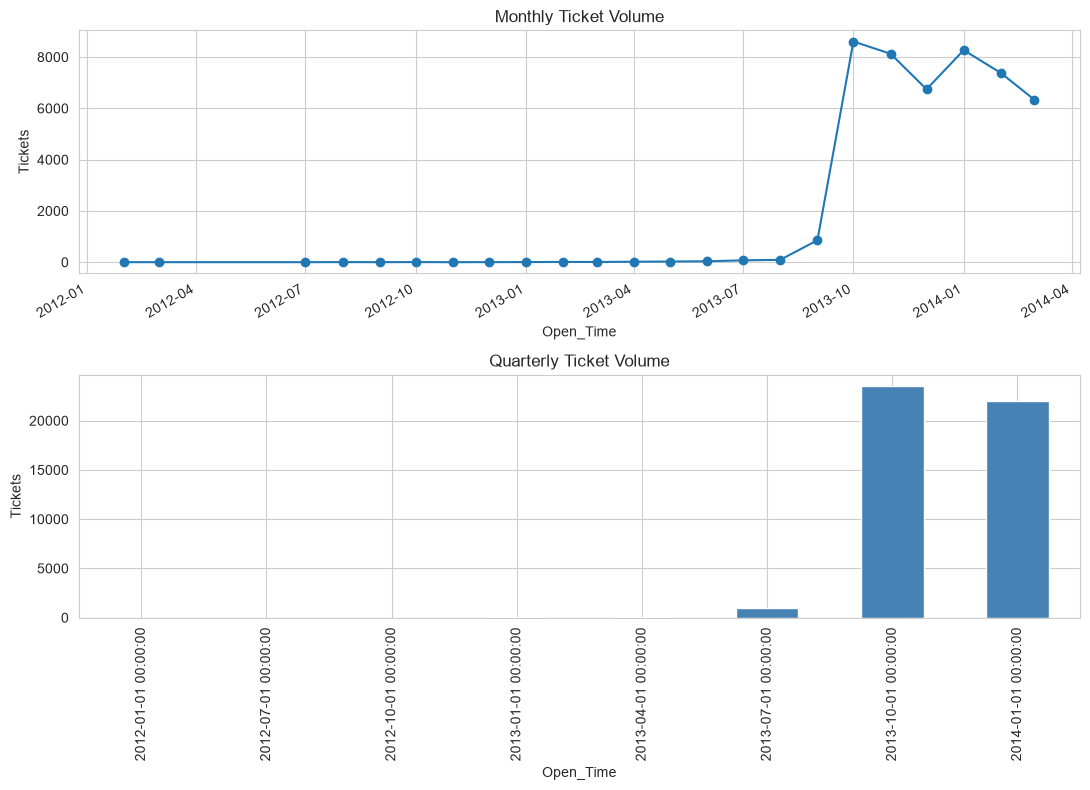

Open_Time
2012-02-01       1
2012-03-01       2
2012-07-01       1
2012-08-01       5
2012-09-01       2
2012-10-01       5
2012-11-01       1
2012-12-01       4
2013-01-01       5
2013-02-01      10
2013-03-01       9
2013-04-01      19
2013-05-01      27
2013-06-01      36
2013-07-01      73
2013-08-01      93
2013-09-01     857
2013-10-01    8606
2013-11-01    8128
2013-12-01    6743
2014-01-01    8270
2014-02-01    7377
2014-03-01    6332
dtype: int64

In [34]:
monthly = df.groupby(df["Open_Time"].dt.to_period('M')).size()
monthly.index = monthly.index.to_timestamp()

quarterly = df.groupby(df["Open_Time"].dt.to_period('Q')).size()
quarterly.index = quarterly.index.to_timestamp()

fig,axes = plt.subplots(2,1,figsize=(11,8))
monthly.plot(ax=axes[0],marker='o')
axes[0].set_title("Monthly Ticket Volume")
axes[0].set_ylabel("Tickets")

quarterly.plot(ax=axes[1],kind='bar',color="steelblue")
axes[1].set_title("Quarterly Ticket Volume")
axes[1].set_ylabel("Tickets")
plt.tight_layout()
plt.show()

monthly

### Data Caveat

Volume ramps from near-Zero (Feb 2012) up to full production scale only from **Sep 2013** onward.
This almost certainly reflects the ITSM system being gradually rolled out / Data Logging starting partway, not real demand growth. **Forecasting is therefore done on the stable production window (Oct 2013 - Mar 2014)** (Sep 2013, at 857 tickets, is still ramp-up and is excluded), which is short (6 months) - forecasts should be treated as a first-pass estimate to refine once more production months are available, not a firm resourcing commitment.

Open_Time
2013-10-01    8606
2013-11-01    8128
2013-12-01    6743
2014-01-01    8270
2014-02-01    7377
2014-03-01    6332
dtype: int64


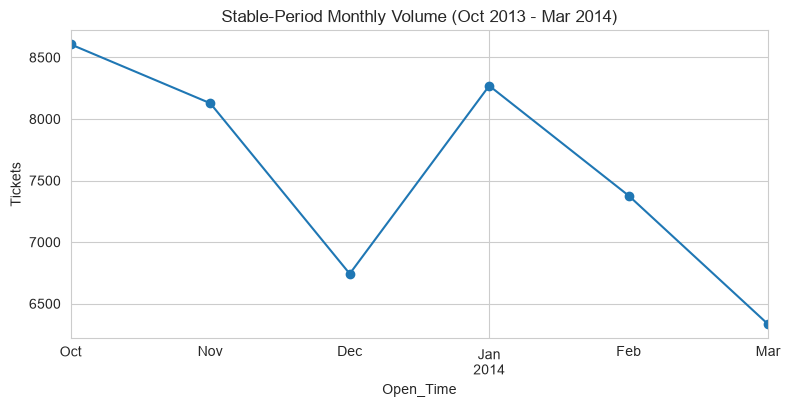

In [35]:
stable = monthly[monthly.index >= '2013-10-01']   # Sep 2013 (857 tickets) was still ramp-up
print(stable)

plt.figure(figsize=(9,4))
stable.plot(marker='o')
plt.title("Stable-Period Monthly Volume (Oct 2013 - Mar 2014)")
plt.ylabel("Tickets")
plt.show()

In [36]:
# stable = monthly[monthly.index >= '2013-09-01']   # Sep 2013 (857 tickets) was still ramp-up
# print(stable)

# plt.figure(figsize=(9,4))
# stable.plot(marker='o')
# plt.title("Stable-Period Monthly Volume (Oct 2013 - Mar 2014)")
# plt.ylabel("Tickets")
# plt.show()

## Train/Holdout split (last 2 months held out)

In [37]:
train = stable.iloc[:-2]
test = stable.iloc[-2:]
print("Train :",train.index.tolist())
print("Test :",test.index.tolist())

Train : [Timestamp('2013-10-01 00:00:00'), Timestamp('2013-11-01 00:00:00'), Timestamp('2013-12-01 00:00:00'), Timestamp('2014-01-01 00:00:00')]
Test : [Timestamp('2014-02-01 00:00:00'), Timestamp('2014-03-01 00:00:00')]


## 15. Forecasting Approaches

### 15.1. Naive baseline - repeat last observed value

In [38]:
naive_forecast = pd.Series([train.iloc[-1]] * len(test),index=test.index)
mae_naive = mean_absolute_error(test,naive_forecast)
print("Naive MAE: ",round(mae_naive,1))

Naive MAE:  1415.5


### 15.2. Linear Trend Regression

In [39]:
from sklearn.linear_model import LinearRegression

X_train = np.arange(len(train)).reshape(-1,1)
y_train = train.values
lr = LinearRegression().fit(X_train,y_train)
X_test = np.arange(len(train),len(train)+len(test)).reshape(-1,1)
lr_forecast = pd.Series(lr.predict(X_test),index=test.index)
mae_lr = mean_absolute_error(test,lr_forecast)
print("Linear Trend MAE:",round(mae_lr,1))

Linear Trend MAE: 402.8


### 15.3. Holt's Exponential Smoothing (trend, no seasonality - too few cycles to estimate seasonality)

In [40]:
hw = ExponentialSmoothing(train,trend='add',seasonal=None,initialization_method='estimated').fit()
hw_forecast = hw.forecast(len(test))
mae_hw = mean_absolute_error(test,hw_forecast)
print("Holt's Linear Trend MAE:",round(mae_hw,1))

Holt's Linear Trend MAE: 402.8


### 15.4. SARIMA (simple order, given the short series)

In [41]:
sarima = SARIMAX(train,order=(1,1,0),enforce_stationarity=False,enforce_invertibility=False).fit(disp=False)
sarima_forecast = sarima.forecast(len(test))
mae_sarima = mean_absolute_error(test,sarima_forecast)
print('SARIMA(1,1,0) MAE:',round(mae_sarima,1))

SARIMA(1,1,0) MAE: 872.2


### 15.5. Hyperparameter Tuning - SARIMA order search

Grid-searching `(p,d,q)` combinations, selecting by **AIC on the training data**, then checking the
selected model's holdout MAE (the equivalent of hyperparameter tuning for a classical time-series
model — there's no train/validation split fine enough with only 5 training points, so AIC is used
in place of cross-validation).

In [42]:
import itertools

# Define ranges for ARIMA parameters p, d, q (values 0, 1, 2)
p = d = q = range(0,3)

# Generate all possible combinations of (p, d, q) using Cartesian product
orders = list(itertools.product(p,d,q))

# Initialize variables to track the best model
best_aic = np.inf        # Start with infinity (so any real AIC will be smaller)
best_order = None        # Placeholder for the best (p,d,q) order
aic_results = []         # List to store (order, AIC) results

# Loop through each possible (p,d,q) combination
for order in orders:
    try:
        # Fit SARIMAX model with current order
        model = SARIMAX(train, order=order,
                       enforce_stationarity=False,
                        enforce_invertibility=False).fit(disp=False)
        
        # Save the order and its AIC score
        aic_results.append((order,model.aic))
        
        # Update best model if current AIC is lower
        if model.aic < best_aic:
            best_aic = model.aic
            best_order = order
    
    # Skip combinations that fail to converge or throw errors
    except Exception:
        continue

# Convert results into a DataFrame, sort by AIC, and show top 10 models
aic_table = pd.DataFrame(aic_results,columns=['order','aic']).sort_values('aic').head(10)

# Print the table of top 10 models
print(aic_table)

# Print the single best order and its AIC score
print("\nBest order by AIC: ", best_order, "AIC: ", round(best_aic, 2))

        order        aic
18  (2, 0, 0) -36.375948
15  (1, 2, 0) -10.680625
21  (2, 1, 0)  -4.429967
11  (1, 0, 2)   2.188123
7   (0, 2, 1)   4.000000
13  (1, 1, 1)   4.371103
8   (0, 2, 2)   6.000000
5   (0, 1, 2)   6.000000
24  (2, 2, 0)   6.000000
16  (1, 2, 1)   6.000000

Best order by AIC:  (2, 0, 0) AIC:  -36.38


In [43]:
sarima_tuned = SARIMAX(train, order=best_order,enforce_stationarity=False,enforce_invertibility=False).fit(disp=False)
sarima_tuned_forecast = sarima_tuned.forecast(len(test))
mae_sarima_tuned = mean_absolute_error(test,sarima_tuned_forecast)

print(f"SARIMA{best_order} (AIC - Tuned) MAE : {round(mae_sarima_tuned,1)}")
print(f"SARIMA(1,1,0)(untuned, from 3d) MAE : {round(mae_sarima,1)}")

SARIMA(2, 0, 0) (AIC - Tuned) MAE : 9575.9
SARIMA(1,1,0)(untuned, from 3d) MAE : 872.2


## 16. Compare Methods on the holdout

In [44]:
# Create a DataFrame to compare actual test values with forecasts from different models
comparison = pd.DataFrame({
    "Actual":test, # Actual observed values from test dataset
    "Naive":naive_forecast, # Forecasts from naive method (e.g., last value carried forward)
    "Linear Trend":lr_forecast, # Forecasts from linear regression trend model
    "Holt Exp. Smoothing":hw_forecast, # Forecasts from Holt’s exponential smoothing
    "SARIMA(1,1,0)":sarima_forecast, # Forecasts from manually chosen SARIMA(1,1,0) model
    f"SARIMA{best_order} (tuned)":sarima_tuned_forecast  # Forecasts from best SARIMA order found via AIC tuning
})

# Round all values to nearest integer for easier comparison
comparison.round(0)

,Actual,Naive,Linear Trend,Holt Exp. Smoothing,"SARIMA(1,1,0)","SARIMA(2, 0, 0) (tuned)"
2014-02-01,7377,8270,7339.0,7338.0,7237.0,1410.0
2014-03-01,6332,8270,7099.0,7099.0,7936.0,19517.0


Holt Exp. Smoothing         402.8
Linear Trend                402.8
SARIMA(1,1,0)               872.2
Naive                      1415.5
SARIMA(2, 0, 0) (tuned)    9575.9
dtype: float64


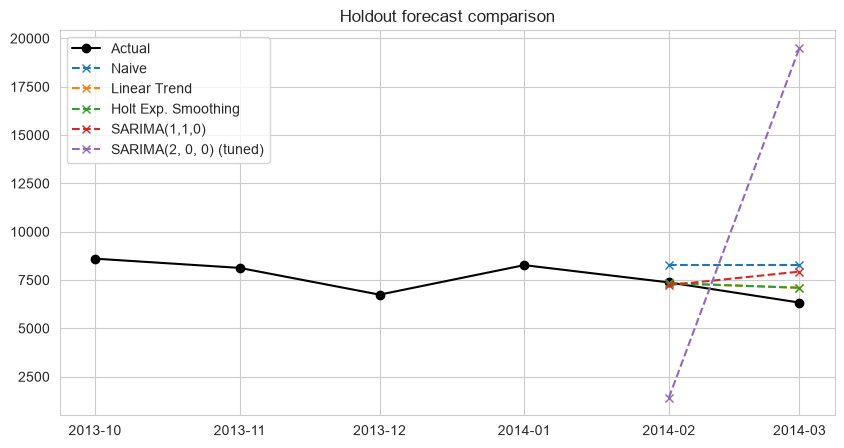

In [45]:
# Create a pandas Series to store MAE values for each model
mae_table = pd.Series({
    "Naive": mae_naive,                     # MAE from naive forecast
    "Linear Trend": mae_lr,                 # MAE from linear trend model
    "Holt Exp. Smoothing": mae_hw,          # MAE from Holt’s exponential smoothing
    "SARIMA(1,1,0)": mae_sarima,            # MAE from manually chosen SARIMA(1,1,0)
    f"SARIMA{best_order} (tuned)": mae_sarima_tuned  # MAE from best SARIMA order found via AIC tuning
}).sort_values()  # Sort models by MAE (lowest error first)

# Print the MAE table rounded to 1 decimal place
print(mae_table.round(1))

# Plot actual vs forecasted values for visual comparison
plt.figure(figsize=(10,5))  # Set figure size

# Plot actual observed values (black line with circle markers)
plt.plot(stable.index, stable.values, marker='o', label='Actual', color='black')

# Plot forecasts from each model (skip 'Actual' column)
for col in comparison.columns[1:]:
    plt.plot(comparison.index, comparison[col], marker='x', linestyle='--', label=col)

# Add chart title and legend
plt.title('Holdout forecast comparison')
plt.legend()

# Display the plot
plt.show()

## 17. Refit best method on all stable-period data & forecast next quarter

In [46]:
# Identify the best forecasting method (lowest MAE from mae_table)
best_method = mae_table.index[0]
print("Best method on holdout: ", best_method)

# Refit the best model on the full stable dataset and forecast next 3 months
if best_method.startswith('SARIMA'):
    # Use tuned SARIMA order if available, else fallback to (1,1,0)
    order_to_use = best_order if 'tuned' in best_method else (1,1,0)
    final_model = SARIMAX(stable, order=order_to_use,
                          enforce_stationarity=False,
                          enforce_invertibility=False).fit(disp=False)
    future = final_model.forecast(3)

elif best_method == "Holt Exp. Smoothing":
    # Fit Holt’s exponential smoothing model with additive trend
    final_model = ExponentialSmoothing(stable, trend='add',
                                       seasonal=None,
                                       initialization_method='estimated').fit()
    future = final_model.forecast(3)

elif best_method == "Linear Trend":
    # Fit linear regression on full series
    X_all = np.arange(len(stable)).reshape(-1, 1)
    lr_final = LinearRegression().fit(X_all, stable.values)
    # Predict next 3 months using future indices
    X_future = np.arange(len(stable), len(stable) + 3).reshape(-1, 1)
    future = pd.Series(lr_final.predict(X_future))

else:
    # Naive forecast: repeat last observed value for next 3 months
    future = pd.Series([stable.iloc[-1]]*3)

# Create date index for next 3 months (monthly start)
future_index = pd.date_range(stable.index[-1] + pd.offsets.MonthBegin(1),
                             periods=3, freq='MS')
future.index = future_index

# Print forecast values rounded to nearest integer
print(future.round(0))

# Calculate and print projected totals
next_quarter_total = future.sum()
print(f"\nProjected next-quarter volume: {next_quarter_total:.0f}  tickets")
print(f"Projected annualized run-rate (x4 quarter): {next_quarter_total*4:.0f}  tickets/year")

Best method on holdout:  Holt Exp. Smoothing
2014-04-01    6366.0
2014-05-01    6021.0
2014-06-01    5675.0
Freq: MS, dtype: float64

Projected next-quarter volume: 18062  tickets
Projected annualized run-rate (x4 quarter): 72250  tickets/year


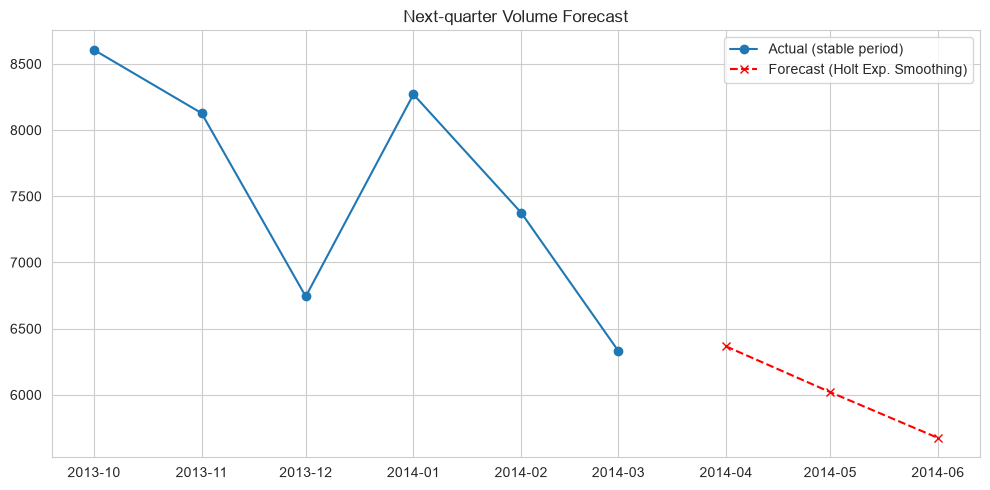

In [47]:
# Create a new figure with size 10x5 inches
plt.figure(figsize=(10, 5))

# Plot actual historical values (stable period) with circle markers
plt.plot(stable.index, stable.values, marker='o',
         label='Actual (stable period)')

# Plot forecasted values for next 3 months using best method
plt.plot(future.index, future.values, marker='x',
         linestyle='--', color='red',
         label=f'Forecast ({best_method})')

# Add chart title
plt.title('Next-quarter Volume Forecast')

# Show legend to distinguish actual vs forecast
plt.legend()

# Adjust layout to prevent overlap
plt.tight_layout()

# Display the plot
plt.show()

## 18. Best model selection & save

In [48]:
with open("best_volume_forecast_model.pkl","wb") as f:
    pickle.dump(final_model,f)

print("Saved final forecasting model to best_volume_forecast_model.pkl")
print("Method Used: ",best_method)

Saved final forecasting model to best_volume_forecast_model.pkl
Method Used:  Holt Exp. Smoothing


## 19. Findings & caveats

- The **best-performing method on the 2-month holdout** was selected automatically above. With
  only 4 training points, differences between methods may not be statistically meaningful, and
  AIC on so few points is unreliable.
- **This is a data-limited forecast.** True seasonality (e.g. year-over-year patterns) cannot be
  estimated with under a year of stable production data. As more months of production data
  accumulate, refit with a seasonal SARIMA or Prophet model with at least 24 months of history.
- Recommend ABC Tech treat the annualized run-rate as a **planning floor**, and re-forecast monthly
  as new data lands, rather than fixing annual resourcing off this single estimate.
- **Check the unit of the brief's "22-25k tickets" figure** against the annualized run-rate printed
  above before presenting the forecast.


# `Use Case 3`
## `Auto Tagging Tickets with Priority & Department`

Goal: auto-tag tickets with the right priority and right department, to reduce reassignment delay.

**Department Proxy:** The dataset has no explicit "department" or "assignment group" field.
`WBS` (WORK BREAKDOWN STRUCTURE CODE) is the closest available proxy for the team/department a ticket is routed to, and is used as the department target here - this assumption should be confirmed against ABC TECH'S actual org. structure before relying on it operationally.

**Leakage note:** only ticket-open-time fields (CI category, request category, timing) are used as predictors - `No_of_Reassignments` (a symptom of *mis*-routing, only known after the fact) is
excluded.

In [49]:
df = pd.read_csv('itsm_cleaned.csv',low_memory=False)
for c in ['CI_Cat','CI_Subcat']:
    df[c] = df[c].fillna('Unknown')

feature_cols = ['CI_Cat','CI_Subcat','Category','Open_DayOfWeek','Open_Year']
cat_cols = ['CI_Cat','CI_Subcat','Category','Open_DayOfWeek']
num_cols = ['Open_Year']

pre = ColumnTransformer([       # pre =preprocessing
    ('cat',OneHotEncoder(handle_unknown='ignore'),cat_cols),
    ('num',StandardScaler(),num_cols)
])               


## 20. Auto-tag Priority (full 5-class)

Use Case 1  already covered *high-priority (P1/P2) vs not* as a binary flag.Here we go further and predict the **full Priority value (1-5)**,again without Impact/Urgency as inputs(those are what an agent would assess manually - the point is to auto-suggest priority before that happens).

In [50]:
# Select feature columns + target column, drop rows with missing values
valid_p = df[feature_cols + ['Priority_filled']].dropna()

# Define input features (Xp) and target labels (yp)
Xp = valid_p[feature_cols]
yp = valid_p['Priority_filled'].astype(int)  # convert to integers

# Print class distribution (number of samples per priority level)
print(yp.value_counts().sort_index())

# Split data into train (80%) and test (20%) sets
Xp_train, Xp_test, yp_train, yp_test = train_test_split(
    Xp, yp, test_size=0.2, random_state=RANDOM_STATE, stratify=yp)

# Build pipeline: preprocessing + Random Forest classifier
priority_clf = Pipeline([
    ('prep', clone(pre)),  # preprocessing step (scaling/encoding)
    ('clf', RandomForestClassifier(
        n_estimators=300,       # number of trees
        max_depth=12,           # limit tree depth
        class_weight='balanced',# handle class imbalance
        random_state=RANDOM_STATE,
        n_jobs=-1               # use all CPU cores
    ))
])

# Train the classifier on training data
priority_clf.fit(Xp_train, yp_train)

# Predict priorities on test set
pred_p = priority_clf.predict(Xp_test)

# Print classification report (precision, recall, F1 per class)
print(classification_report(yp_test, pred_p, zero_division=0))

# Print overall accuracy and macro-F1 score
print("Accuracy:", accuracy_score(yp_test, pred_p),
      "Macro-F1:", f1_score(yp_test, pred_p, average='macro'))

Priority_filled
1        3
2      697
3     5323
4    22717
5    16486
Name: count, dtype: int64
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         1
           2       0.36      0.62      0.45       139
           3       0.24      0.76      0.37      1065
           4       0.73      0.51      0.60      4544
           5       0.91      0.59      0.72      3297

    accuracy                           0.57      9046
   macro avg       0.45      0.50      0.43      9046
weighted avg       0.73      0.57      0.61      9046

Accuracy: 0.5731815166924608 Macro-F1: 0.42796855273004714


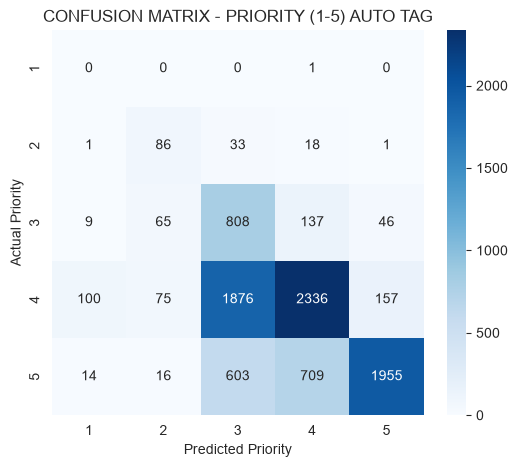

In [51]:
cm_p = confusion_matrix(yp_test,pred_p,labels=sorted(yp.unique()))
plt.figure(figsize=(6,5))
sns.heatmap(cm_p,annot=True,fmt='d',cmap='Blues',xticklabels=sorted(yp.unique()),yticklabels=sorted(yp.unique()))
plt.title('CONFUSION MATRIX - PRIORITY (1-5) AUTO TAG')
plt.xlabel("Predicted Priority")
plt.ylabel("Actual Priority")
plt.show()

### Compare against a naive baseline

Since Priority 3 dominates the data, check whether the model beats simply always predicting the
majority class.

In [52]:
# Find the majority class in training labels (most frequent value)
majority_class = yp_train.mode()[0]

# Create baseline predictions: always predict the majority class for all test samples
baseline_pred = pd.Series([majority_class] * len(yp_test))

# Evaluate baseline accuracy (naive benchmark)
print(f"Majority-class baseline ('{majority_class}') accuracy:",
      accuracy_score(yp_test, baseline_pred))

# Evaluate Random Forest accuracy for comparison
print(f"Random Forest accuracy:",
      accuracy_score(yp_test, pred_p))

Majority-class baseline ('4') accuracy: 0.5023214680521778
Random Forest accuracy: 0.5731815166924608


## 21. Auto-tag Department (via WBS proxy)

`WBS` has 274 distinct values. To keep the task tractable and the results interpretable, we model
the **top 15 WBS groups** (covering ~65% of tickets) individually and bucket the rest as `Other`.

Dept_Group
Others       16424
WBS000073    13342
WBS000091     2500
WBS000263     2283
WBS000072     2197
WBS000271     1186
WBS000095     1102
WBS000318     1099
WBS000152     1076
WBS000094      861
WBS000146      858
WBS000223      803
WBS000092      784
WBS000128      755
WBS000099      717
WBS000088      619
Name: count, dtype: int64


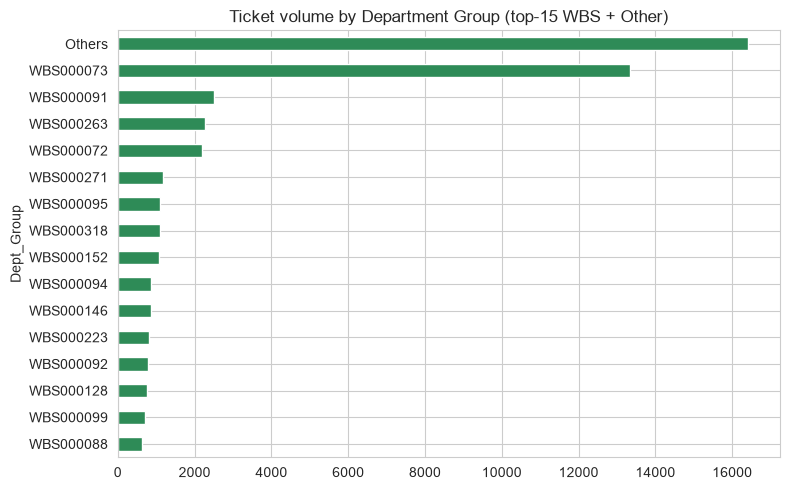

In [53]:
# Find the top 15 most frequent WBS values (departments)
top_wbs = df['WBS'].value_counts().head(15).index

# Create a new column 'Dept_Group':
# - If WBS is in top 15, keep it
# - Otherwise, label it as 'Others'
df['Dept_Group'] = df['WBS'].where(df['WBS'].isin(top_wbs), 'Others')

# Print ticket counts per department group
print(df['Dept_Group'].value_counts())

# Plot ticket volume by department group
plt.figure(figsize=(8,5))  # Set figure size
df['Dept_Group'].value_counts().plot(kind='barh', color='seagreen')  # Horizontal bar chart
plt.title("Ticket volume by Department Group (top-15 WBS + Other)")  # Add title
plt.gca().invert_yaxis()  # Largest bar at the top (flips the y-axis so the largest bar appears at the top.)
plt.tight_layout()        # Adjust layout
plt.show()                # Display chart


In [54]:
# Prepare input features (Xd) and target labels (yd)
Xd = df[feature_cols].dropna()  # Drop rows with missing feature values
yd = df.loc[Xd.index, 'Dept_Group']  # Align target labels with valid feature rows

# Split data into training (80%) and testing (20%) sets
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    Xd, yd, test_size=0.2, random_state=RANDOM_STATE, stratify=yd)

# Build pipeline: preprocessing + Random Forest classifier
dept_clf = Pipeline([
    ('prep', clone(pre)),  # preprocessing step (e.g., scaling, encoding)
    ('clf', RandomForestClassifier(
        n_estimators=300,       # number of trees
        max_depth=15,           # limit tree depth
        class_weight='balanced',# handle class imbalance
        random_state=RANDOM_STATE,
        n_jobs=-1               # use all CPU cores
    ))
])

# Train the classifier on training data
dept_clf.fit(Xd_train, yd_train)

# Predict department groups on test set
pred_d = dept_clf.predict(Xd_test)

# Print classification report (precision, recall, F1 per class)
print(classification_report(yd_test, pred_d))

# Print overall accuracy and macro-F1 score
print("Accuracy:", accuracy_score(yd_test, pred_d),
      " Macro-F1:", f1_score(yd_test, pred_d, average='macro'))

              precision    recall  f1-score   support

      Others       0.95      0.19      0.31      3285
   WBS000072       0.40      0.97      0.57       439
   WBS000073       0.84      0.42      0.56      2669
   WBS000088       0.10      0.68      0.17       124
   WBS000091       0.88      0.89      0.89       500
   WBS000092       0.26      0.77      0.39       157
   WBS000094       0.32      0.62      0.43       172
   WBS000095       0.81      0.99      0.89       220
   WBS000099       0.06      0.42      0.10       143
   WBS000128       0.81      0.65      0.72       151
   WBS000146       0.93      1.00      0.97       172
   WBS000152       0.11      0.27      0.15       215
   WBS000223       0.07      0.58      0.12       161
   WBS000263       0.27      0.01      0.01       457
   WBS000271       0.99      1.00      1.00       237
   WBS000318       0.11      0.17      0.14       220

    accuracy                           0.42      9322
   macro avg       0.49   

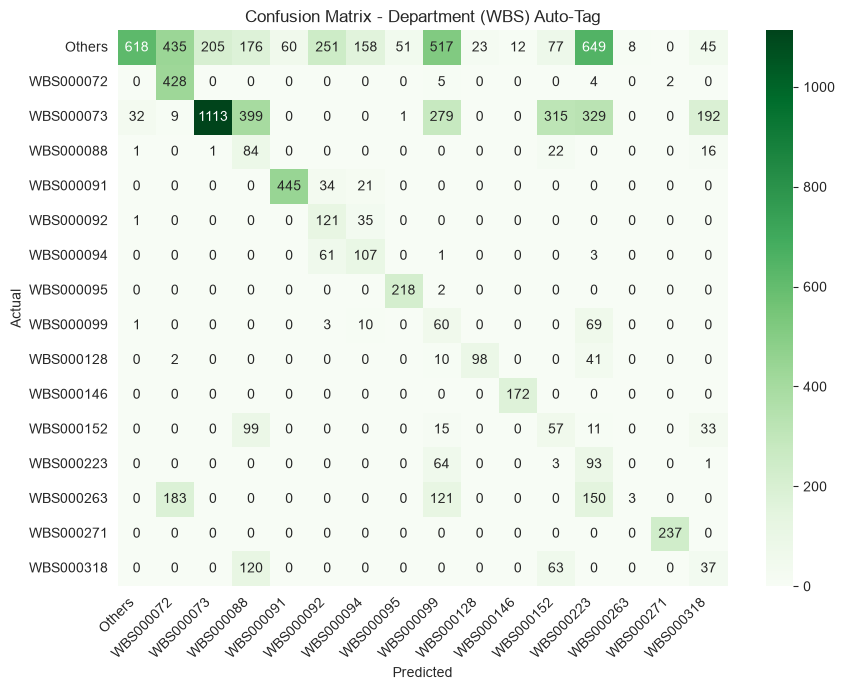

In [55]:
cm_d = confusion_matrix(yd_test, pred_d, labels=dept_clf.classes_)
plt.figure(figsize=(9,7))
sns.heatmap(cm_d, annot=True, fmt='d', cmap='Greens', xticklabels=dept_clf.classes_, yticklabels=dept_clf.classes_)
plt.title("Confusion Matrix - Department (WBS) Auto-Tag")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [56]:
majority_dept = yd_train.mode()[0]
baseline_dept_pred = pd.Series([majority_dept] * len(yd_test))
print(f"Majority Class Baseline ('{majority_dept}') accuracy:",accuracy_score(yd_test,baseline_dept_pred))
print(f"Random Forest Accuracy:",accuracy_score(yd_test,pred_d))

Majority Class Baseline ('Others') accuracy: 0.35239219051705645
Random Forest Accuracy: 0.4173996996352714


## 22. Hyperparameter Tuning

Tuning the Random Forest for both the Priority and Department models via `RandomizedSearchCV`,
scored on **macro-F1** (treats all classes equally, appropriate since we care about getting every
priority/department right, not just the majority class).

In [57]:
# Define cross-validation strategy (3-fold stratified CV)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# Define hyperparameter search space for Random Forest
rf_param_dist = {
    'clf__n_estimators': [100, 200, 300],   # number of trees
    'clf__max_depth': [8, 12, None],        # tree depth (None = unlimited)
    'clf__min_samples_leaf': [1, 5, 10],    # minimum samples per leaf
}

# Set up RandomizedSearchCV for Priority classification
priority_search = RandomizedSearchCV(
    Pipeline([
        ('prep', clone(pre)),  # preprocessing step
        ('clf', RandomForestClassifier(
            class_weight='balanced',        # handle class imbalance
            random_state=RANDOM_STATE,
            n_jobs=1                        # run on single core
        ))
    ]),
    rf_param_dist,          # hyperparameter ranges
    n_iter=6,               # number of random combinations to try
    scoring='f1_macro',     # evaluation metric (Macro-F1)
    cv=cv,                  # cross-validation strategy
    random_state=RANDOM_STATE,
    n_jobs=1
)

# Fit search on training data
priority_search.fit(Xp_train, yp_train)

# Print best parameters and best CV score
print("Best Priority model params:", priority_search.best_params_)
print("Best Priority CV macro-f1:", round(priority_search.best_score_, 4))

# Predict on test set using tuned model
pred_p_tuned = priority_search.best_estimator_.predict(Xp_test)

# Print classification report for tuned model
print("\nTuned Priority test performance:")
print(classification_report(yp_test, pred_p_tuned, zero_division=0))

# Compare performance before vs after tuning
print("Before tuning  - Accuracy:", round(accuracy_score(yp_test, pred_p), 4),
      " Macro-F1:", round(f1_score(yp_test, pred_p, average='macro'), 4))
print("After tuning   - Accuracy:", round(accuracy_score(yp_test, pred_p_tuned), 4),
      " Macro-F1:", round(f1_score(yp_test, pred_p_tuned, average='macro'), 4))

Best Priority model params: {'clf__n_estimators': 100, 'clf__min_samples_leaf': 1, 'clf__max_depth': 12}
Best Priority CV macro-f1: 0.438

Tuned Priority test performance:
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         1
           2       0.36      0.62      0.46       139
           3       0.24      0.76      0.37      1065
           4       0.73      0.51      0.60      4544
           5       0.91      0.59      0.72      3297

    accuracy                           0.57      9046
   macro avg       0.45      0.50      0.43      9046
weighted avg       0.73      0.57      0.61      9046

Before tuning  - Accuracy: 0.5732  Macro-F1: 0.428
After tuning   - Accuracy: 0.5735  Macro-F1: 0.4288


### DEPARTMENT TUNING

In [58]:
# --- Department tuning ---
# Set up RandomizedSearchCV for Department classification
dept_search = RandomizedSearchCV(
    Pipeline([
        ('prep', clone(pre)),  # preprocessing step
        ('clf', RandomForestClassifier(
            class_weight='balanced',        # handle class imbalance
            random_state=RANDOM_STATE,
            n_jobs=1                        # run on single core
        ))
    ]),
    rf_param_dist,          # hyperparameter ranges
    n_iter=6,               # number of random combinations to try
    scoring='f1_macro',     # evaluation metric (Macro-F1 score)
    cv=cv,                  # cross-validation strategy (StratifiedKFold)
    random_state=RANDOM_STATE,
    n_jobs=1
)

# Fit search on training data
dept_search.fit(Xd_train, yd_train)

# Print best parameters and best CV score
print("Best Department model params:", dept_search.best_params_)
print("Best Department CV macro-f1:", round(dept_search.best_score_, 4))

# Predict on test set using tuned model
pred_d_tuned = dept_search.best_estimator_.predict(Xd_test)

# Print classification report for tuned model
print("\nTuned Department test performance:")
print(classification_report(yd_test, pred_d_tuned, zero_division=0))

# Compare performance before vs after tuning
print("Before tuning  - Accuracy:", round(accuracy_score(yd_test, pred_d), 4),
      " Macro-F1:", round(f1_score(yd_test, pred_d, average='macro'), 4))
print("After tuning   - Accuracy:", round(accuracy_score(yd_test, pred_d_tuned), 4),
      " Macro-F1:", round(f1_score(yd_test, pred_d_tuned, average='macro'), 4))

Best Department model params: {'clf__n_estimators': 100, 'clf__min_samples_leaf': 1, 'clf__max_depth': 12}
Best Department CV macro-f1: 0.4625

Tuned Department test performance:
              precision    recall  f1-score   support

      Others       0.94      0.18      0.31      3285
   WBS000072       0.40      0.97      0.57       439
   WBS000073       0.85      0.42      0.56      2669
   WBS000088       0.10      0.68      0.17       124
   WBS000091       0.85      0.89      0.87       500
   WBS000092       0.26      0.77      0.39       157
   WBS000094       0.32      0.62      0.43       172
   WBS000095       0.81      0.99      0.89       220
   WBS000099       0.06      0.42      0.10       143
   WBS000128       0.81      0.65      0.72       151
   WBS000146       0.93      1.00      0.97       172
   WBS000152       0.10      0.08      0.09       215
   WBS000223       0.07      0.58      0.12       161
   WBS000263       0.27      0.01      0.01       457
   WBS0002

## 23. Best model selection & save & sample prediction

In [59]:
# ---------- Pick the best Priority model (tuned vs untuned) ----------
# Calculate Macro-F1 scores for untuned and tuned Priority models
priority_untuned_f1 = f1_score(yp_test, pred_p, average='macro')
priority_tuned_f1 = f1_score(yp_test, pred_p_tuned, average='macro')

# Choose the better Priority model based on Macro-F1
if priority_tuned_f1 >= priority_untuned_f1:
    best_priority_model = priority_search.best_estimator_  # tuned model
    print(f"Best Priority Model: tuned Random Forest (Macro-F1={priority_tuned_f1:.4f})")
else:
    best_priority_model = priority_clf  # untuned model
    print(f"Best Priority Model: untuned Random Forest (Macro-F1={priority_untuned_f1:.4f})")

# Save the chosen Priority model to a file
with open("best_priority_autotag_model.pkl", "wb") as f:
    pickle.dump(best_priority_model, f)
print("Saved to best_priority_autotag_model.pkl")

# ---------- Pick the best Department model (tuned vs untuned) ----------
# Calculate Macro-F1 scores for untuned and tuned Department models
dept_untuned_f1 = f1_score(yd_test, pred_d, average="macro")
dept_tuned_f1 = f1_score(yd_test, pred_d_tuned, average="macro")

# Choose the better Department model based on Macro-F1
if dept_tuned_f1 >= dept_untuned_f1:
    best_dept_model = dept_search.best_estimator_  # tuned model
    print(f"\nBest Department Model: tuned Random Forest (Macro-F1={dept_tuned_f1:.4f})")
else:
    best_dept_model = dept_clf  # untuned model
    print(f"\nBest Department Model: untuned Random Forest (Macro-F1={dept_untuned_f1:.4f})")

# Save the chosen Department model to a file
with open("best_department_autotag_model.pkl", "wb") as f:
    pickle.dump(best_dept_model, f)
print("Saved to best_department_autotag_model.pkl")


Best Priority Model: tuned Random Forest (Macro-F1=0.4288)
Saved to best_priority_autotag_model.pkl

Best Department Model: untuned Random Forest (Macro-F1=0.4627)
Saved to best_department_autotag_model.pkl


In [60]:
# ---------- Load both saved models ----------
with open("best_priority_autotag_model.pkl", "rb") as f:
    loaded_priority_model = pickle.load(f)

with open("best_department_autotag_model.pkl", "rb") as f:
    loaded_dept_model = pickle.load(f)

# ---------- Sample new ticket (same 5 columns as feature_cols) ----------
new_ticket = pd.DataFrame([{
    "CI_Cat": "application",              # Configuration Item category
    "CI_Subcat": "Web Based Application", # Subcategory
    "Category": "incident",               # Ticket type
    "Open_DayOfWeek": "Monday",           # Day ticket opened
    "Open_Year": 2014                     # Year ticket opened
}])

# ---------- Predict ----------
# Predict Priority and Department using loaded models
predicted_priority = loaded_priority_model.predict(new_ticket)[0]
predicted_dept = loaded_dept_model.predict(new_ticket)[0]

print(f"Predicted Priority: {predicted_priority}")
print(f"Predicted Department (WBS): {predicted_dept}")

# Show full probability breakdown across all classes
priority_proba = pd.Series(
    loaded_priority_model.predict_proba(new_ticket)[0],
    index = loaded_priority_model.classes_
).sort_values(ascending=False)

dept_proba = pd.Series(
    loaded_dept_model.predict_proba(new_ticket)[0],
    index = loaded_dept_model.classes_
).sort_values(ascending=False)

print("\nPriority probability breakdown:")
print(priority_proba)

print("\nDepartment probability breakdown (top 5):")
print(dept_proba.head())

Predicted Priority: 4
Predicted Department (WBS): WBS000152

Priority probability breakdown:
4    0.407652
5    0.227240
3    0.185549
2    0.157607
1    0.021952
dtype: float64

Department probability breakdown (top 5):
WBS000152    0.286243
WBS000318    0.283003
WBS000088    0.212195
WBS000073    0.150350
Others       0.034477
dtype: float64


## Findings & recommendation

- **Priority auto-tag:** 57.3% accuracy vs 50.2% majority-class baseline (macro-F1 0.428; tuned
  0.429). A modest gain: best used as a **suggested default** the agent can override, not a fully
  automated assignment, especially early on.
- **Department auto-tag (WBS proxy):** 41.7% accuracy vs 35.2% majority-class baseline (macro-F1
  0.4627). Tuning did not help (macro-F1 0.4627 -> 0.4601, accuracy 0.4174 -> 0.4161), so the
  untuned model was kept. The gain over baseline is similar to priority, and several WBS groups are
  barely learned (e.g. WBS000263 recall 0.01, "Others" recall 0.19).
- **Caveat:** `WBS` is used as a stand-in for "department" because no explicit department/assignment
  group field exists in this dataset: confirm with ABC Tech whether WBS codes map 1:1 to support
  teams before treating this model as routing-ready.
- Adding the ticket's free-text description (not present in this extract) would likely improve both
  auto-tagging tasks substantially.


### NLP extension for Use Case 3: using ticket text (TF-IDF)

The models above use only metadata (CI category, request category, timing). Priority and department are much easier to
tell apart from **what the ticket says**, so this section adds ticket text as TF-IDF features and compares the same
classifier **without** and **with** text on the same train/test split.

**Important:** this dataset has **no ticket text column**. With `NLP_USE_DEMO_TEXT = True` a made-up text column is built
only from existing columns plus random filler words, so it adds **no real information**: it is only there to prove the
code runs, and its scores are **not meaningful**. When ABC Tech provides real ticket descriptions, set
`NLP_USE_DEMO_TEXT = False` and set `NLP_TEXT_COL` to the real column name. The text must be known **when the ticket is
opened** (title/description), not notes written after resolution.

In [61]:
from sklearn.feature_extraction.text import TfidfVectorizer

NLP_TEXT_COL = "Description"     # change to the real text column name
NLP_USE_DEMO_TEXT = True         # set to False once real ticket text is available

nlp_df = df.copy()
for c in ["CI_Cat", "CI_Subcat"]:
    nlp_df[c] = nlp_df[c].fillna("Unknown")

if NLP_USE_DEMO_TEXT:
    _rng = np.random.default_rng(RANDOM_STATE)
    _filler = ["error", "login", "slow", "failed", "access", "restart", "update", "timeout",
               "request", "issue", "unable", "screen", "network", "password"]
    nlp_df[NLP_TEXT_COL] = [f"{sub} {cat} " + " ".join(_rng.choice(_filler, 3))
                            for sub, cat in zip(nlp_df["CI_Subcat"], nlp_df["Category"])]
    print("USING DEMO TEXT: NLP scores below are NOT meaningful.")
else:
    nlp_df[NLP_TEXT_COL] = nlp_df[NLP_TEXT_COL].fillna("").astype(str)

# department proxy: top-15 WBS groups + Others (same as above)
_top_wbs = nlp_df["WBS"].value_counts().head(15).index
nlp_df["Dept_Group"] = nlp_df["WBS"].where(nlp_df["WBS"].isin(_top_wbs), "Others")

nlp_cat_cols = ["CI_Cat", "CI_Subcat", "Category", "Open_DayOfWeek"]
nlp_num_cols = ["Open_Year"]
nlp_cols = nlp_cat_cols + nlp_num_cols + [NLP_TEXT_COL]

nlp_df[[NLP_TEXT_COL]].head()

USING DEMO TEXT: NLP scores below are NOT meaningful.


,Description
0,Web Based Application incident login unable issue
1,Web Based Application incident update update n...
2,Desktop Application request for information lo...
3,Web Based Application incident login timeout p...
4,Web Based Application incident unable unable u...


In [62]:
def nlp_make_model(use_text):
    parts = []
    if use_text:
        parts.append(("text", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=20000,
                                              sublinear_tf=True, stop_words="english"), NLP_TEXT_COL))
    parts.append(("cat", OneHotEncoder(handle_unknown="ignore"), nlp_cat_cols))
    parts.append(("num", StandardScaler(), nlp_num_cols))
    return Pipeline([("prep", ColumnTransformer(parts)),          # new preprocessor per model
                     ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", C=1.0))])

nlp_results = []

def nlp_run(task, target, X_df, y, show_report=True):
    X_tr, X_te, y_tr, y_te = train_test_split(X_df, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
    maj = accuracy_score(y_te, np.full(len(y_te), y_tr.mode()[0]))
    nlp_results.append({"Task": task, "Model": "Majority-class baseline", "Accuracy": round(maj, 4), "Macro-F1": np.nan})
    print(f"=== {task} ===")
    print(f"{'Majority-class baseline':40s} accuracy={maj:.4f}")
    fitted = {}
    for label, use_text in [("Logistic Regression, no text", False), ("Logistic Regression + text (NLP)", True)]:
        m = nlp_make_model(use_text).fit(X_tr, y_tr)
        pred = m.predict(X_te)
        acc, f1m = accuracy_score(y_te, pred), f1_score(y_te, pred, average="macro")
        nlp_results.append({"Task": task, "Model": label, "Accuracy": round(acc, 4), "Macro-F1": round(f1m, 4)})
        print(f"{label:40s} accuracy={acc:.4f}  macro-F1={f1m:.4f}")
        fitted[label] = m
    final = fitted["Logistic Regression + text (NLP)"]
    if show_report:
        print("\nClassification report (+ text):")
        print(classification_report(y_te, final.predict(X_te), zero_division=0))
    return final

# ---- Priority (1-5) ----
_p = nlp_df[nlp_cols + ["Priority_filled"]].dropna()
priority_nlp_model = nlp_run("Priority (1-5)", "Priority_filled", _p[nlp_cols], _p["Priority_filled"].astype(int))

# ---- Department (WBS proxy) ----
_d = nlp_df[nlp_cols + ["Dept_Group"]].dropna()
dept_nlp_model = nlp_run("Department (WBS proxy)", "Dept_Group", _d[nlp_cols], _d["Dept_Group"])

=== Priority (1-5) ===
Majority-class baseline                  accuracy=0.5023
Logistic Regression, no text             accuracy=0.5817  macro-F1=0.4278
Logistic Regression + text (NLP)         accuracy=0.5868  macro-F1=0.4035

Classification report (+ text):
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         1
           2       0.20      0.63      0.30       139
           3       0.25      0.70      0.37      1065
           4       0.73      0.55      0.63      4544
           5       0.90      0.59      0.72      3297

    accuracy                           0.59      9046
   macro avg       0.42      0.49      0.40      9046
weighted avg       0.73      0.59      0.62      9046

=== Department (WBS proxy) ===
Majority-class baseline                  accuracy=0.3524
Logistic Regression, no text             accuracy=0.4125  macro-F1=0.4593
Logistic Regression + text (NLP)         accuracy=0.4161  macro-F1=0.4435

Classificatio

In [63]:
# ---------- Summary: metadata-only Random Forest (from above) vs Logistic Regression with / without text ----------
nlp_summary = pd.DataFrame(nlp_results)
if "pred_p" in globals() and "yp_test" in globals():
    nlp_summary.loc[len(nlp_summary)] = ["Priority (1-5)", "Random Forest, metadata only (from above)",
                                         round(accuracy_score(yp_test, pred_p), 4),
                                         round(f1_score(yp_test, pred_p, average="macro"), 4)]
if "pred_d" in globals() and "yd_test" in globals():
    nlp_summary.loc[len(nlp_summary)] = ["Department (WBS proxy)", "Random Forest, metadata only (from above)",
                                         round(accuracy_score(yd_test, pred_d), 4),
                                         round(f1_score(yd_test, pred_d, average="macro"), 4)]
display(nlp_summary.sort_values(["Task", "Accuracy"]).reset_index(drop=True))

# ---------- Save the text-based models and try a sample ticket ----------
with open("best_priority_nlp_model.pkl", "wb") as f:
    pickle.dump(priority_nlp_model, f)
with open("best_department_nlp_model.pkl", "wb") as f:
    pickle.dump(dept_nlp_model, f)

with open("best_priority_nlp_model.pkl", "rb") as f:
    loaded_priority_nlp = pickle.load(f)
with open("best_department_nlp_model.pkl", "rb") as f:
    loaded_dept_nlp = pickle.load(f)

nlp_ticket = pd.DataFrame([{
    "CI_Cat": "application", "CI_Subcat": "Web Based Application", "Category": "incident",
    "Open_DayOfWeek": "Monday", "Open_Year": 2014,
    NLP_TEXT_COL: "Unable to login to web application, error after password reset",
}])
print("Predicted priority  :", loaded_priority_nlp.predict(nlp_ticket)[0])
print("Predicted department:", loaded_dept_nlp.predict(nlp_ticket)[0])

,Task,Model,Accuracy,Macro-F1
0,Department (WBS proxy),Majority-class baseline,0.3524,NaN
1,Department (WBS proxy),"Logistic Regression, no text",0.4125,0.4593
2,Department (WBS proxy),Logistic Regression + text (NLP),0.4161,0.4435
3,Department (WBS proxy),"Random Forest, metadata only (from above)",0.4174,0.4627
4,Priority (1-5),Majority-class baseline,0.5023,NaN
5,Priority (1-5),"Random Forest, metadata only (from above)",0.5732,0.4280
6,Priority (1-5),"Logistic Regression, no text",0.5817,0.4278
7,Priority (1-5),Logistic Regression + text (NLP),0.5868,0.4035


Predicted priority  : 4
Predicted department: WBS000318


### NLP findings & next steps

- Compare each **"+ text (NLP)"** row with its **"no text"** row: the gap is what ticket text adds. With the demo text
  the gap is about zero (or slightly negative), which is expected because the demo text carries no real information.
- With **real** ticket descriptions, text should help most for **department routing** (the words in a ticket point to the
  right team) and for **priority** (words like "down", "outage", "all users", "urgent").
- **Next step:** obtain the ticket title/description field from ABC Tech's ITSM system, set `NLP_USE_DEMO_TEXT = False`,
  set `NLP_TEXT_COL`, and re-run this section. Use only text available when the ticket is opened.
- Keep using the models as **suggestions** an agent can override, and confirm that `WBS` maps to real support teams.

# `Use Case 4`
## `Predicting RFC (Request for Change) & Likely Fault / Misconfiguration Category`

Goal : predict RFC and possible failure/misconfiguration of ITSM assets.

This splits into two related, ticket-open-time predictions:
- **4a. Will this ticket need a Request for Change?** — binary classification, proxied from
  whether the ticket ends up linked to a change record (`No_of_Related_Changes` / `Related_Change`).
- **4b. What kind of fault is this likely to be?** — a multi-class prediction of the eventual
  `Closure_Code` fault category (Hardware / Software / Data / User error / Operator error / etc.),
  i.e. an early read on whether this looks like a misconfiguration issue, before it's diagnosed.

**Leakage note:** `Related_Change`, `No_of_Related_Changes` and `Closure_Code` are only known
*after* a ticket is worked — they're used here strictly as **labels to predict**, never as input
features. Only ticket-open-time fields (CI category, request category, priority/impact/urgency,
timing) are used as predictors.

In [64]:
df = pd.read_csv('itsm_cleaned.csv',low_memory=False)
for c in ['CI_Cat','CI_Subcat']:
    df[c] = df[c].fillna('Unknown')

## 24. `PART A - Will this ticket need an RFC?`

Has_RFC
0    0.987984
1    0.012016
Name: share, dtype: float64


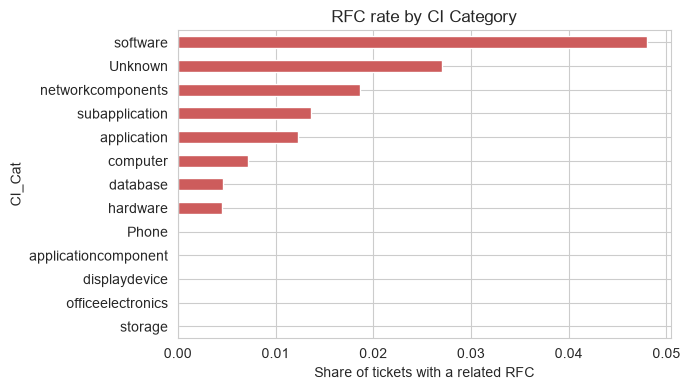

In [65]:
# Create a binary flag 'Has_RFC':
# - 1 if ticket has related changes or a non-null Related_Change
# - 0 otherwise
df["Has_RFC"] = ((df["No_of_Related_Changes"].fillna(0) > 0) |
                 df["Related_Change"].notna()).astype(int)

# Print share of tickets with/without RFC
print(df["Has_RFC"].value_counts(normalize=True).rename("share"))

# Plot RFC rate by CI Category
plt.figure(figsize=(7,4))  # Set figure size
df.groupby("CI_Cat")["Has_RFC"].mean() \
  .sort_values(ascending=False) \
  .plot(kind="barh", color="indianred")  # Horizontal bar chart

plt.title("RFC rate by CI Category")  # Chart title
plt.xlabel("Share of tickets with a related RFC")  # X-axis label
plt.gca().invert_yaxis()  # Largest bar at the top
plt.tight_layout()        # Adjust layout
plt.show()                # Display chart

Only ~1.2% of tickets end up RFC-linked, but the rate varies meaningfully by CI category
(software CIs are ~4x the baseline rate) — there's real signal to model, despite the imbalance.

In [66]:
# Define feature columns
feature_cols = ['CI_Cat', 'CI_Subcat', 'Category', 'Priority_filled',
                'Impact', 'Urgency', 'Open_DayOfWeek', 'Open_Year']

# Prepare feature matrix (drop rows with missing values)
X = df[feature_cols].dropna()

# Align target labels (Has_RFC) with valid feature rows
y_rfc = df.loc[X.index, 'Has_RFC']

# Separate categorical and numerical columns
cat_cols = ['CI_Cat', 'CI_Subcat', 'Category', 'Open_DayOfWeek']
num_cols = ['Priority_filled', 'Impact', 'Urgency', 'Open_Year']

# Define preprocessing pipeline:
# - OneHotEncoder for categorical columns
# - StandardScaler for numerical columns
pre = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('num', StandardScaler(), num_cols)
])

# Split into training (80%) and testing (20%) sets
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X, y_rfc, test_size=0.2, random_state=RANDOM_STATE, stratify=y_rfc)

# Print shapes of train and test sets
print(Xr_train.shape, Xr_test.shape)

(36180, 8) (9046, 8)


In [67]:
# Define candidate models for RFC prediction
rfc_models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(
        max_depth=6, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, max_depth=10, class_weight='balanced',
        random_state=RANDOM_STATE, n_jobs=-1)
}

# Dictionaries to store results and fitted models
rfc_results = {}
rfc_fitted = {}

# Loop through each model
for name, clf in rfc_models.items():
    # Build pipeline with preprocessing + classifier
    pipe = Pipeline([('prep', clone(pre)), ('clf', clf)])
    
    # Train the model
    pipe.fit(Xr_train, yr_train)
    
    # Predict probabilities and classes on test set
    proba = pipe.predict_proba(Xr_test)[:, 1]  # probability of class 1 (Has_RFC)
    pred = pipe.predict(Xr_test)               # predicted labels
    
    # Store evaluation metrics
    rfc_results[name] = {
        'roc_auc': roc_auc_score(yr_test, proba),
        'pr_auc': average_precision_score(yr_test, proba)
    }
    rfc_fitted[name] = pipe  # save fitted pipeline
    
    # Print classification report and metrics
    print(f"--- {name} ---")
    print(classification_report(yr_test, pred, zero_division=0))
    print(f"ROC-AUC: {rfc_results[name]['roc_auc']:.3f}  PR-AUC:{rfc_results[name]['pr_auc']:.3f}\n")

--- Logistic Regression ---
              precision    recall  f1-score   support

           0       0.99      0.63      0.77      8941
           1       0.02      0.71      0.04       105

    accuracy                           0.63      9046
   macro avg       0.51      0.67      0.41      9046
weighted avg       0.98      0.63      0.76      9046

ROC-AUC: 0.713  PR-AUC:0.025

--- Decision Tree ---
              precision    recall  f1-score   support

           0       1.00      0.66      0.79      8941
           1       0.02      0.72      0.05       105

    accuracy                           0.66      9046
   macro avg       0.51      0.69      0.42      9046
weighted avg       0.98      0.66      0.78      9046

ROC-AUC: 0.754  PR-AUC:0.049

--- Random Forest ---
              precision    recall  f1-score   support

           0       1.00      0.69      0.82      8941
           1       0.03      0.73      0.05       105

    accuracy                           0.69      9

Best RFC model: Random Forest


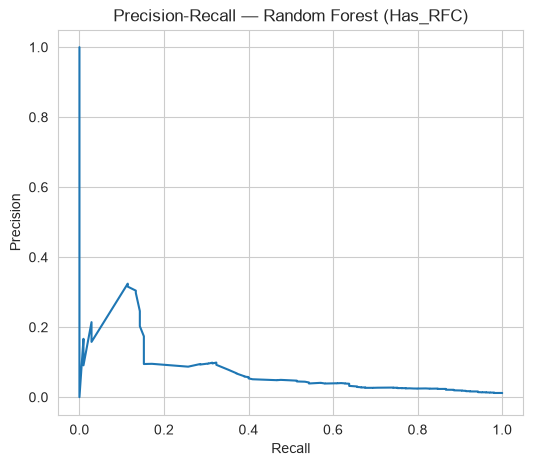

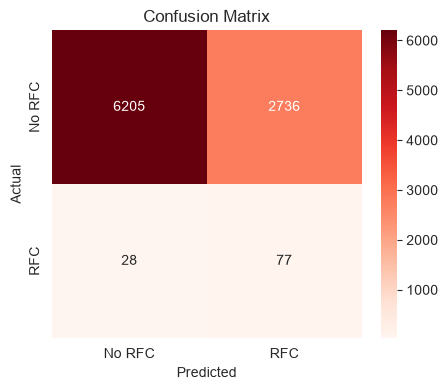

In [68]:
# Find the best RFC model based on PR-AUC score
best_rfc_name = max(rfc_results, key=lambda k: rfc_results[k]['pr_auc'])
print("Best RFC model:", best_rfc_name)

# Retrieve the fitted pipeline for the best model
best_rfc_pipe = rfc_fitted[best_rfc_name]

# Compute precision-recall curve for the best model
proba = best_rfc_pipe.predict_proba(Xr_test)[:, 1]  # probabilities for class 1 (Has_RFC)
prec, rec, thresh = precision_recall_curve(yr_test, proba)

# Plot Precision-Recall curve
plt.figure(figsize=(6,5))
plt.plot(rec, prec)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall — {best_rfc_name} (Has_RFC)')
plt.show()

# Build confusion matrix for predictions
cm = confusion_matrix(yr_test, best_rfc_pipe.predict(Xr_test))

# Plot confusion matrix as heatmap
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=['No RFC','RFC'], yticklabels=['No RFC','RFC'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

## 25. `Likely fault/misconfiguration category (from Closure_Code)`

In [69]:
print(df['Closure_Code'].value_counts())

Closure_Code
Other                           16470
Software                        13027
User error                       3554
No error - works as designed     3530
Hardware                         2999
Data                             2209
Unknown                          1590
Operator error                   1539
User manual not used              765
Inquiry                           162
Referred                          158
Questions                         132
Kwaliteit van de output            10
Overig                              1
Name: count, dtype: int64


Fault_Category
Other/Unknown             18983
Software                  13027
User error                 4319
No fault (as designed)     3530
Hardware                   2999
Data                       2209
Operator error             1539
Name: count, dtype: int64


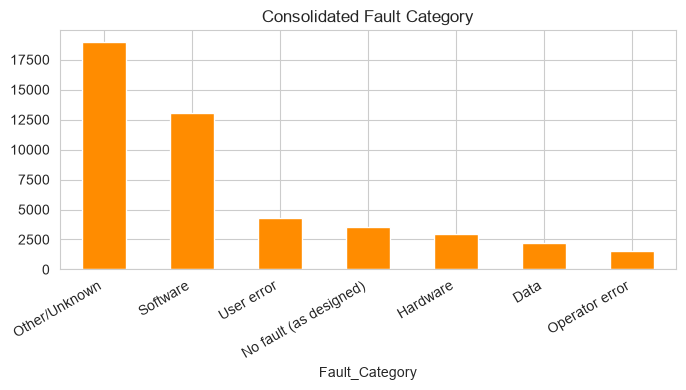

In [70]:
# Define mapping from closure codes to consolidated fault categories
fault_map = {
    "Hardware": "Hardware",
    "Software": "Software",
    "Data": "Data",
    "User error": "User error",
    "Operator error": "Operator error",
    "No error - works as designed": "No fault (as designed)",
    "User manual not used": "User error"
}

# Create new column 'Fault_Category' using the mapping
# - If Closure_Code matches dictionary, map to category
# - If not found, assign 'Other/Unknown'
df["Fault_Category"] = df["Closure_Code"].map(fault_map).fillna('Other/Unknown')

# Print counts of tickets per fault category
print(df["Fault_Category"].value_counts())

# Plot distribution of fault categories
plt.figure(figsize=(7, 4))  # Set figure size
df["Fault_Category"].value_counts().plot(kind='bar', color='darkorange')  # Bar chart
plt.title("Consolidated Fault Category")  # Chart title
plt.xticks(rotation=30, ha="right")       # Rotate x-axis labels for readability
plt.tight_layout()                        # Adjust layout
plt.show()                                # Display chart

In [71]:
Xf = df[feature_cols].dropna()
yf = df.loc[Xf.index, 'Fault_Category']

Xf_train, Xf_test, yf_train, yf_test = train_test_split(
    Xf, yf, test_size=0.2, random_state=RANDOM_STATE, stratify=yf)

fault_clf = Pipeline([
    ('prep', clone(pre)),
    ('clf', RandomForestClassifier(n_estimators=300, max_depth=12, class_weight='balanced',
                                  random_state=RANDOM_STATE, n_jobs=-1))
])
fault_clf.fit(Xf_train, yf_train)
pred_f = fault_clf.predict(Xf_test)
print(classification_report(yf_test, pred_f, zero_division=0))

                        precision    recall  f1-score   support

                  Data       0.20      0.32      0.24       429
              Hardware       0.45      0.80      0.58       566
No fault (as designed)       0.19      0.17      0.18       690
        Operator error       0.07      0.48      0.12       300
         Other/Unknown       0.75      0.31      0.44      3710
              Software       0.49      0.40      0.44      2543
            User error       0.24      0.31      0.27       808

              accuracy                           0.36      9046
             macro avg       0.34      0.40      0.33      9046
          weighted avg       0.52      0.36      0.39      9046



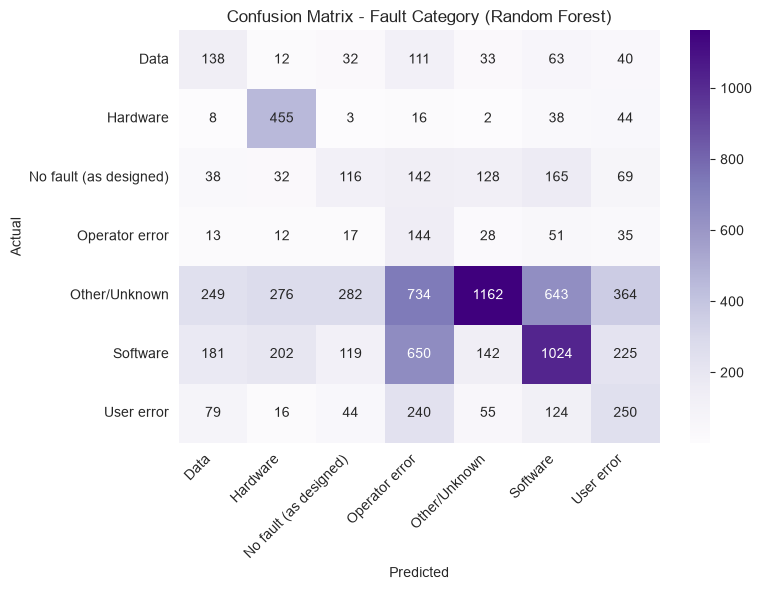

In [72]:
cm_f = confusion_matrix(yf_test, pred_f, labels=fault_clf.classes_)
plt.figure(figsize=(8,6))
sns.heatmap(cm_f, annot=True, fmt='d', cmap='Purples', xticklabels=fault_clf.classes_, yticklabels=fault_clf.classes_)
plt.title("Confusion Matrix - Fault Category (Random Forest)")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

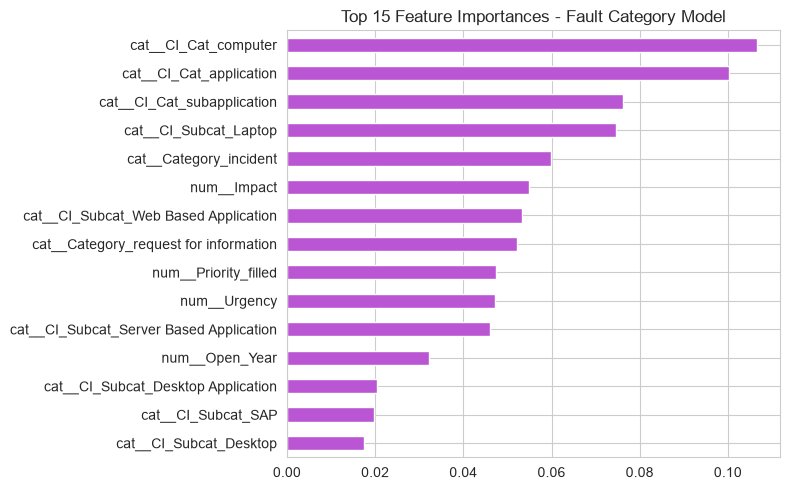

In [73]:
rf = fault_clf.named_steps['clf']
feat_names = fault_clf.named_steps['prep'].get_feature_names_out()
importances = pd.Series(rf.feature_importances_, index=feat_names).sort_values(ascending=False).head(15)
plt.figure(figsize=(8,5))
importances.plot(kind='barh', color='mediumorchid')
plt.title("Top 15 Feature Importances - Fault Category Model")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 26. `Hyperparameter tuning`

Tuning both classifiers via `RandomizedSearchCV`: the RFC model on **PR-AUC** (given the ~1.2%
positive rate), and the fault-category model on **macro-F1** (multi-class, all categories matter).

In [74]:
# Define cross-validation strategy (3-fold stratified CV)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# Define hyperparameter search space for Random Forest
rf_param_dist = {
    'clf__n_estimators': [100, 200, 300],   # number of trees
    'clf__max_depth': [8, 12, None],        # tree depth (None = unlimited)
    'clf__min_samples_leaf': [1, 5, 10]     # minimum samples per leaf
}

# --- RFC (Part A) tuning ---
# Set up RandomizedSearchCV for RFC prediction
rfc_search = RandomizedSearchCV(
    Pipeline([
        ('prep', clone(pre)),  # preprocessing step
        ('clf', RandomForestClassifier(
            class_weight='balanced',        # handle class imbalance
            random_state=RANDOM_STATE,
            n_jobs=1                        # run on single core
        ))
    ]),
    rf_param_dist,          # hyperparameter ranges
    n_iter=6,               # number of random combinations to try
    scoring='average_precision',  # evaluation metric (PR-AUC)
    cv=cv,                  # cross-validation strategy
    random_state=RANDOM_STATE,
    n_jobs=1
)

# Fit search on training data
rfc_search.fit(Xr_train, yr_train)

# Print best parameters and best CV score
print("Best RFC model params:", rfc_search.best_params_)
print("Best RFC CV PR-AUC:", round(rfc_search.best_score_, 4))

# Predict on test set using tuned model
proba_tuned = rfc_search.best_estimator_.predict_proba(Xr_test)[:,1]
pred_tuned = rfc_search.best_estimator_.predict(Xr_test)

# Print classification report for tuned model
print("\nTuned RFC test performance:")
print(classification_report(yr_test, pred_tuned, zero_division=0))

# Compare PR-AUC before vs after tuning
print("Before tuning - PR-AUC:", round(rfc_results[best_rfc_name]['pr_auc'], 4))
print("After tuning  - PR-AUC:", round(average_precision_score(yr_test, proba_tuned), 4))

Best RFC model params: {'clf__n_estimators': 200, 'clf__min_samples_leaf': 5, 'clf__max_depth': 12}
Best RFC CV PR-AUC: 0.0636

Tuned RFC test performance:
              precision    recall  f1-score   support

           0       1.00      0.69      0.81      8941
           1       0.03      0.77      0.05       105

    accuracy                           0.69      9046
   macro avg       0.51      0.73      0.43      9046
weighted avg       0.98      0.69      0.81      9046

Before tuning - PR-AUC: 0.0829
After tuning  - PR-AUC: 0.0906


### FAULTY CATEGORY (PART B) TUNING

In [75]:
# --- Fault category (Part B) tuning ---
# Set up RandomizedSearchCV for Fault Category classification
fault_search = RandomizedSearchCV(
    Pipeline([
        ('prep', clone(pre)),  # preprocessing step
        ('clf', RandomForestClassifier(
            class_weight='balanced',        # handle class imbalance
            random_state=RANDOM_STATE,
            n_jobs=1                        # run on single core
        ))
    ]),
    rf_param_dist,          # hyperparameter ranges
    n_iter=6,               # number of random combinations to try
    scoring='f1_macro',     # evaluation metric (Macro-F1 score)
    cv=cv,                  # cross-validation strategy
    random_state=RANDOM_STATE,
    n_jobs=1
)

# Fit search on training data
fault_search.fit(Xf_train, yf_train)

# Print best parameters and best CV score
print("Best RFC model params:", fault_search.best_params_)
print("Best RFC CV Macro-F1:", round(fault_search.best_score_, 4))

# Predict on test set using tuned model
pred_f_tuned = fault_search.best_estimator_.predict(Xf_test)

# Print classification report for tuned model
print("\nTuned RFC test performance:")
print(classification_report(yf_test, pred_f_tuned, zero_division=0))

# Compare performance before vs after tuning
print("Before tuning - Macro-F1:", round(f1_score(yf_test, pred_f, average='macro'), 4))
print("After tuning  - Macro-F1:", round(f1_score(yf_test, pred_f_tuned, average='macro'), 4))

Best RFC model params: {'clf__n_estimators': 300, 'clf__min_samples_leaf': 10, 'clf__max_depth': 8}
Best RFC CV Macro-F1: 0.333

Tuned RFC test performance:
                        precision    recall  f1-score   support

                  Data       0.31      0.22      0.26       429
              Hardware       0.42      0.81      0.55       566
No fault (as designed)       0.21      0.11      0.14       690
        Operator error       0.07      0.34      0.12       300
         Other/Unknown       0.73      0.34      0.46      3710
              Software       0.45      0.48      0.46      2543
            User error       0.20      0.36      0.26       808

              accuracy                           0.39      9046
             macro avg       0.34      0.38      0.32      9046
          weighted avg       0.50      0.39      0.40      9046

Before tuning - Macro-F1: 0.3255
After tuning  - Macro-F1: 0.3219


## Findings & recommendation

- **RFC prediction (Part A)** is a rare-event problem (~1.2% positive) but not a hopeless one —
  CI category alone shifts the rate by ~4x, and the PR-AUC above shows how much lift the model
  gets over the base rate. Recommend deploying as a **flag for review**, not an automatic gate:
  route tickets above a tuned probability threshold to a change-management reviewer rather than
  auto-creating RFCs.
- **Fault category prediction (Part B)** gives an early, pre-diagnosis read on whether a ticket
  is likely Hardware / Software / Data / a user or operator error — useful for routing to the
  right specialist team at open time rather than waiting for manual triage. Check the confusion
  matrix above for which categories the model confuses most (commonly Software vs. "No fault -
  as designed", since both can look similar from ticket metadata alone).
- Both models use only CI category, request category, and priority/impact/urgency — none of the
  ticket's free-text description was available in this dataset. Adding a text field (ticket
  summary/description) in a future data pull would likely improve both tasks substantially.

## 27. Best model selection & save & sample prediction

In [76]:
# ---------- Part A: best RFC model (judged on PR-AUC) ----------
# Get PR-AUC scores for untuned and tuned RFC models
untuned_rfc_pr = rfc_results[best_rfc_name]['pr_auc']
tuned_rfc_pr = average_precision_score(yr_test,
                                       rfc_search.best_estimator_.predict_proba(Xr_test)[:,1])

# Choose the better RFC model based on PR-AUC
if tuned_rfc_pr >= untuned_rfc_pr:
    best_rfc_model = rfc_search.best_estimator_  # tuned model
    print(f"Best RFC model: tuned Random Forest (PR-AUC={tuned_rfc_pr:.4f})")
else:
    best_rfc_model = rfc_fitted[best_rfc_name]   # untuned model
    print(f"Best RFC model: untuned {best_rfc_name} (PR-AUC={untuned_rfc_pr:.4f})")

# Save the chosen RFC model
with open("best_rfc_model.pkl", "wb") as f:
    pickle.dump(best_rfc_model, f)
print("Saved to best_rfc_model.pkl")

# ---------- Part B: best fault-category model (judged on macro-F1) ----------
# Get Macro-F1 scores for untuned and tuned fault models
untuned_fault_f1 = f1_score(yf_test, pred_f, average='macro')
tuned_fault_f1 = f1_score(yf_test, pred_f_tuned, average='macro')

# Choose the better fault model based on Macro-F1
if tuned_fault_f1 >= untuned_fault_f1:
    best_fault_model = fault_search.best_estimator_  # tuned model
    print(f"\nBest fault model: tuned Random Forest (Macro-F1={tuned_fault_f1:.4f})")
else:
    best_fault_model = fault_clf  # untuned model
    print(f"\nBest fault model: untuned Random Forest (Macro-F1={untuned_fault_f1:.4f})")

# Save the chosen fault model
with open("best_fault_model.pkl", "wb") as f:
    pickle.dump(best_fault_model, f)
print("Saved to best_fault_model.pkl")

Best RFC model: tuned Random Forest (PR-AUC=0.0906)
Saved to best_rfc_model.pkl

Best fault model: untuned Random Forest (Macro-F1=0.3255)
Saved to best_fault_model.pkl


In [77]:
# ---------- Load both models ----------
with open("best_rfc_model.pkl", "rb") as f:
    loaded_rfc_model = pickle.load(f)

with open("best_fault_model.pkl", "rb") as f:
    loaded_fault_model = pickle.load(f)

# ---------- Sample new ticket (all 8 columns in feature_cols) ----------
new_ticket = pd.DataFrame([{
    'CI_Cat': 'software',                  # Configuration Item category
    'CI_Subcat': 'Server Based Application', # Subcategory
    'Category': 'incident',                # Ticket type
    'Priority_filled': 3,                  # Priority level
    'Impact': 3,                           # Impact score
    'Urgency': 3,                          # Urgency score
    'Open_DayOfWeek': 'Monday',            # Day ticket opened
    'Open_Year': 2014                      # Year ticket opened
}])

# ---------- Part A: will this ticket need an RFC? ----------
rfc_pred = loaded_rfc_model.predict(new_ticket)[0]          # 0 = No RFC, 1 = Needs RFC
rfc_prob = loaded_rfc_model.predict_proba(new_ticket)[0, 1] # Probability of RFC
print("Needs RFC (1 = yes, 0 = no):", rfc_pred)
print(f"Probability of needing an RFC: {rfc_prob:.2%}")

# ---------- Part B: likely fault category ----------
fault_pred = loaded_fault_model.predict(new_ticket)[0]      # Predicted fault category
fault_proba = pd.Series(
    loaded_fault_model.predict_proba(new_ticket)[0],
    index=loaded_fault_model.classes_
).sort_values(ascending=False)

print("\nPredicted fault category:", fault_pred)
print("Fault probability breakdown:")
print(fault_proba.round(4))


Needs RFC (1 = yes, 0 = no): 1
Probability of needing an RFC: 61.19%

Predicted fault category: User error
Fault probability breakdown:
User error                0.2978
Data                      0.2156
Hardware                  0.1434
Operator error            0.0964
Other/Unknown             0.0963
Software                  0.0852
No fault (as designed)    0.0652
dtype: float64


## 1. Model Comparison Report
### Use Case 1: Predicting high-priority (P1/P2) tickets

Tickets with unknown Priority are now excluded. The test set has 9,046 tickets, 140 of them high priority (1.5%). These results use Feature Set B (no Impact or Urgency).

Model	ROC-AUC	PR-AUC	Precision	Recall	F1
KNN (k=15, untuned)	0.862	0.461	0.64	0.43	0.51
KNN (tuned)	0.869	0.458	0.68	0.29	0.40
Decision Tree	0.889	0.447	0.41	0.73	0.53
Random Forest (tuned)	0.897	0.441	0.28	0.74	0.41
Random Forest (untuned)	0.896	0.439	0.33	0.74	0.46
Logistic Regression (untuned and tuned)	0.901	0.424	0.23	0.74	0.35
SVM (RBF)	0.869	0.289	0.21	0.75	0.32
Best model: untuned KNN has the highest PR-AUC (0.461), about 30 times the base rate. It is also the saved final model.
The top models are close. KNN, Decision Tree and Random Forest are within 0.02 PR-AUC of each other, and with only 140 positives that gap is within noise. Cross-validation on the training data points the other way: tuned Random Forest scored 0.374, Logistic Regression 0.360 and KNN 0.334.
They trade precision for recall. KNN is cautious: 64% of its flags are right but it catches only 43% of high-priority tickets. Random Forest catches 74% but only 33% of its flags are right.
Tuning: it did not meaningfully help any model.
Feature Set A (with Impact and Urgency): every model scored 1.000, because Priority is derived from those two fields. It confirms the data is consistent but isn’t a usable model.
Use Case 2: Forecasting incident volume

The series covers Oct 2013 to Mar 2014 (6 months): 4 for training and 2 for holdout.

Method	MAE (tickets/month)
Holt exponential smoothing	402.8
Linear trend	402.8
SARIMA(1,1,0)	872.2
Naive (last value)	1,415.5
SARIMA(2,0,0), AIC-tuned	9,575.9
Selected method: Holt, which ties with the linear trend.
Forecast for Apr–Jun 2014: 6,366, 6,021 and 5,675 tickets, which is 18,062 for the quarter, or about 72,250 a year.
AIC tuning backfired. It picked SARIMA(2,0,0), which produced the worst holdout error by a wide margin (its forecasts were 1,410 and 19,517 against actuals of 7,377 and 6,332). An AIC score from 4 data points is not meaningful.
Use Case 3: Auto-tagging priority and department
Task	Model	Accuracy	Macro-F1	Majority baseline accuracy
Priority (1–5)	Random Forest (tuned, saved)	57.4%	0.429	50.2%
Department (top-15 WBS + Others)	Random Forest (untuned, saved)	41.7%	0.463	35.2%

Tuning moved priority macro-F1 from 0.428 to 0.429. For department, tuning made it slightly worse (0.4627 to 0.4601), so the untuned model was kept.

Use Case 4: RFC and fault-category prediction
Task	Model	ROC-AUC	PR-AUC
Needs an RFC? (1.2% positive, 105 test positives)	Random Forest (tuned, saved)	–	0.091
	Random Forest (untuned)	0.790	0.083
	Decision Tree	0.754	0.049
	Logistic Regression	0.713	0.025
Task	Model	Accuracy	Macro-F1
Fault category (7 classes)	Random Forest (untuned, saved)	36%	0.326
	Random Forest (tuned)	39%	0.322

The tuned RFC model recalls 77% of RFC tickets but with only 3% precision.